# NutriRota — Análise e Modelagem de Preços CONAB

## 1. Objetivo
Analisar a evolução mensal dos preços de produtos de frutas, legumes e verduras (FLV) comercializados em entrepostos atacadistas e preparar uma base temporal para desenvolver modelos de previsão de preços.

## 2. Fonte dos dados
Boletim Hortigranjeiro da Companhia Nacional de Abastecimento (CONAB), edição de outubro de 2026, arquivo de dados disponibilizado em `data/raw/`.

A planilha contém séries mensais de setembro de 2024 a setembro de 2026 para dez produtos e doze CEASAs. Nas dez abas `Preços-*`, os títulos identificam a variável como **Preço Médio (R$/kg)**. Portanto, a unidade registrada para todos os dez produtos, inclusive alface, é reais por quilograma.

## 3. Unidade de análise
Cada observação representa a combinação de **produto × CEASA × mês de referência** (`produto`, `ceasa`, `data_ref`), com o preço médio em R$/kg.

## 4. Relação com os Notebooks 1 e 2
Os Notebooks 1 e 2 investigam o desperdício de alimentos em feiras livres paulistanas (estudo de Brancoli et al.) e a distribuição territorial das feiras cadastradas pela Prefeitura de São Paulo. Este notebook complementa essa investigação com informações de preços atacadistas de dez produtos de FLV. Esses produtos ajudam a contextualizar a dinâmica de abastecimento e os preços de alimentos relevantes para o ambiente das feiras, mas **os preços da CONAB não medem desperdício nem representam diretamente os preços praticados nas feiras livres**.

O recorte nacional das CEASAs amplia a comparação de mercado; a CEAGESP — São Paulo será destacada nas análises territoriais relacionadas ao projeto.

## 5. Escopo e limitações
A série possui 25 referências mensais por produto e CEASA. A quantidade de linhas do painel não equivale ao mesmo número de períodos temporais independentes. As análises e a validação dos modelos deverão respeitar a ordem cronológica. A previsão desenvolvida aqui tem como alvo o **preço médio (R$/kg)**, não o volume de excedente ou desperdício de alimentos.


In [1]:
from pathlib import Path
import pandas as pd

RAIZ = Path.cwd().parent

CAMINHO_XLSX = (
    RAIZ / "data" / "raw" /
    "tabelas-de-dados-boletim-hortigranjeiro-outubro-2026.xlsx"
)

CAMINHO_SAIDA = (
    RAIZ / "data" / "processed" /
    "conab_precos_consolidados.csv"
)

produtos = {
    "Alface": "Hortaliças",
    "Batata": "Hortaliças",
    "Cebola": "Hortaliças",
    "Cenoura": "Hortaliças",
    "Tomate": "Hortaliças",
    "Banana": "Frutas",
    "Laranja": "Frutas",
    "Maçã": "Frutas",
    "Mamão": "Frutas",
    "Melancia": "Frutas"
}

ufs = {
    "Ceagesp - São Paulo": "SP",
    "CeasaMinas - Belo Horizonte": "MG",
    "Ceasa/RJ - Rio de Janeiro": "RJ",
    "Ceasa/SP - Campinas": "SP",
    "Ceasa/ES - Vitória": "ES",
    "Ceasa/PR - Curitiba": "PR",
    "Ceasa/SC - São José": "SC",
    "Ceasa/GO - Goiânia": "GO",
    "Ceasa/DF - Brasília": "DF",
    "Ceasa/PE - Recife": "PE",
    "Ceasa/CE - Fortaleza": "CE",
    "Ceasa/AC - Rio Branco": "AC"
}

registros = []

for produto, grupo in produtos.items():

    aba = pd.read_excel(
        CAMINHO_XLSX,
        sheet_name=f"Preços-{produto}",
        header=None
    )

    datas = pd.to_datetime(
        aba.iloc[3, 1:],
        errors="coerce"
    )

    dados = aba.iloc[4:].copy()

    for _, linha in dados.iterrows():

        nome_ceasa = linha.iloc[0]

        if pd.isna(nome_ceasa):
            continue

        nome_ceasa = str(nome_ceasa).strip()

        # Remove marcador de nota de rodapé
        nome_ceasa = nome_ceasa.rstrip("*").strip()

        if nome_ceasa not in ufs:
            continue

        for coluna, data_ref in enumerate(datas, start=1):

            if pd.isna(data_ref):
                continue

            preco = pd.to_numeric(
                linha.iloc[coluna],
                errors="coerce"
            )

            registros.append({
                "produto": produto,
                "grupo": grupo,
                "ceasa": nome_ceasa,
                "uf": ufs[nome_ceasa],
                "data_ref": data_ref,
                "ano": data_ref.year,
                "mes": data_ref.month,
                "preco": preco
            })

df_conab = pd.DataFrame(registros)

df_conab = df_conab.sort_values(
    ["produto", "ceasa", "data_ref"]
).reset_index(drop=True)

# Validações
assert len(df_conab) == 3000
assert df_conab["produto"].nunique() == 10
assert (df_conab.groupby("produto")["data_ref"].nunique() == 25).all()
assert (df_conab.groupby("produto")["ceasa"].nunique() == 12).all()
assert not df_conab.duplicated(
    ["produto", "ceasa", "data_ref"]
).any()
assert df_conab["uf"].isna().sum() == 0

# Exportação
CAMINHO_SAIDA.parent.mkdir(
    parents=True,
    exist_ok=True
)

df_conab.to_csv(
    CAMINHO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

print("Dimensão:", df_conab.shape)
print("Ausentes:", df_conab["preco"].isna().sum())
print("Zeros:", df_conab["preco"].eq(0).sum())
print("CEASAs sem UF:", df_conab[df_conab["uf"].isna()]["ceasa"].unique())

display(df_conab.head())

Dimensão: (3000, 8)
Ausentes: 249
Zeros: 20
CEASAs sem UF: <ArrowStringArray>
[]
Length: 0, dtype: str


,produto,grupo,ceasa,uf,data_ref,ano,mes,preco
0,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-09-01,2024,9,2.278246
1,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-10-01,2024,10,2.369917
2,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-11-01,2024,11,4.775193
3,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-12-01,2024,12,4.218470
4,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-01-01,2025,1,2.984938


In [2]:
# 1. Visão geral
display(df_conab.info())

# 2. Estatísticas descritivas
display(df_conab["preco"].describe())

# 3. Valores ausentes por produto
display(
    df_conab.groupby("produto")["preco"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

# 4. Valores iguais a zero por produto
display(
    df_conab[df_conab["preco"].eq(0)]
    .groupby("produto")
    .size()
    .sort_values(ascending=False)
)

# 5. Ausentes por CEASA
display(
    df_conab.groupby("ceasa")["preco"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   produto   3000 non-null   str           
 1   grupo     3000 non-null   str           
 2   ceasa     3000 non-null   str           
 3   uf        3000 non-null   str           
 4   data_ref  3000 non-null   datetime64[us]
 5   ano       3000 non-null   int64         
 6   mes       3000 non-null   int64         
 7   preco     2751 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 298.9 KB


None

count    2751.000000
mean        4.281605
std         2.474588
min         0.000000
25%         2.520000
50%         3.573698
75%         5.198073
max        13.623918
Name: preco, dtype: float64

produto
Batata      27
Cebola      26
Tomate      26
Maçã        26
Cenoura     26
Melancia    25
Laranja     24
Alface      24
Mamão       24
Banana      21
Name: preco, dtype: int64

produto
Alface      2
Banana      2
Batata      2
Cebola      2
Cenoura     2
Laranja     2
Mamão       2
Maçã        2
Melancia    2
Tomate      2
dtype: int64

ceasa
Ceasa/DF - Brasília            227
Ceasa/GO - Goiânia              20
Ceasa/AC - Rio Branco            2
Ceagesp - São Paulo              0
Ceasa/CE - Fortaleza             0
Ceasa/ES - Vitória               0
Ceasa/PE - Recife                0
Ceasa/PR - Curitiba              0
Ceasa/RJ - Rio de Janeiro        0
Ceasa/SC - São José              0
Ceasa/SP - Campinas              0
CeasaMinas - Belo Horizonte      0
Name: preco, dtype: int64

In [3]:
# Ausências por produto e CEASA
ausencias = (
    df_conab.assign(
        ausente=df_conab["preco"].isna()
    )
    .pivot_table(
        index="produto",
        columns="ceasa",
        values="ausente",
        aggfunc="sum",
        fill_value=0
    )
)

display(ausencias)

ceasa,Ceagesp - São Paulo,Ceasa/AC - Rio Branco,Ceasa/CE - Fortaleza,Ceasa/DF - Brasília,Ceasa/ES - Vitória,Ceasa/GO - Goiânia,Ceasa/PE - Recife,Ceasa/PR - Curitiba,Ceasa/RJ - Rio de Janeiro,Ceasa/SC - São José,Ceasa/SP - Campinas,CeasaMinas - Belo Horizonte
produto,,,,,,,,,,,,
Alface,0,0,0,22,0,2,0,0,0,0,0,0
Banana,0,0,0,19,0,2,0,0,0,0,0,0
Batata,0,1,0,24,0,2,0,0,0,0,0,0
Cebola,0,0,0,24,0,2,0,0,0,0,0,0
Cenoura,0,0,0,24,0,2,0,0,0,0,0,0
Laranja,0,0,0,22,0,2,0,0,0,0,0,0
Mamão,0,0,0,22,0,2,0,0,0,0,0,0
Maçã,0,0,0,24,0,2,0,0,0,0,0,0
Melancia,0,1,0,22,0,2,0,0,0,0,0,0


In [4]:
cobertura = (
    df_conab.groupby("ceasa")
    .agg(
        total_registros=("preco", "size"),
        precos_validos=("preco", "count"),
        ausentes=("preco", lambda x: x.isna().sum())
    )
)

cobertura["cobertura_pct"] = (
    cobertura["precos_validos"] /
    cobertura["total_registros"] * 100
).round(2)

display(
    cobertura.sort_values("cobertura_pct")
)

,total_registros,precos_validos,ausentes,cobertura_pct
ceasa,,,,
Ceasa/DF - Brasília,250,23,227,9.2
Ceasa/GO - Goiânia,250,230,20,92.0
Ceasa/AC - Rio Branco,250,248,2,99.2
Ceagesp - São Paulo,250,250,0,100.0
Ceasa/CE - Fortaleza,250,250,0,100.0
Ceasa/ES - Vitória,250,250,0,100.0
Ceasa/PE - Recife,250,250,0,100.0
Ceasa/PR - Curitiba,250,250,0,100.0
Ceasa/RJ - Rio de Janeiro,250,250,0,100.0


## 6. Critério de seleção das CEASAs

A análise de qualidade identificou diferenças significativas na disponibilidade dos dados entre as centrais de abastecimento.

A CEASA de Brasília apresentou apenas 9,2% de cobertura bruta (23 de 250 registros) e foi excluída da base principal de modelagem, preservando-se seus registros na base consolidada original.

Goiânia apresentou inicialmente 92,0% de cobertura bruta (230 de 250 registros). Entretanto, os dez preços iguais a zero identificados em setembro de 2026 — um para cada produto — foram classificados como suspeitos e convertidos em valores ausentes (`NaN`) na base de modelagem. Assim, sua cobertura útil após o tratamento é de 88,0% (220 de 250 registros).

Rio Branco apresentou 99,2% de cobertura bruta (248 de 250 registros) e foi mantida, assim como as nove CEASAs com cobertura integral. Os valores ausentes foram preservados, sem imputação nesta etapa.

Após excluir Brasília, a base contém 2.750 registros distribuídos entre 11 CEASAs e 10 produtos. Após o tratamento dos dez zeros suspeitos, há 32 preços ausentes: 22 originalmente ausentes e dez classificados como suspeitos.


In [5]:
# Seleção das CEASAs com cobertura adequada

ceasas_excluidas = [
    "Ceasa/DF - Brasília"
]

df_modelagem = df_conab[
    ~df_conab["ceasa"].isin(ceasas_excluidas)
].copy()

print("Dimensão:", df_modelagem.shape)
print("CEASAs:", df_modelagem["ceasa"].nunique())
print("Valores ausentes:", df_modelagem["preco"].isna().sum())
print("Zeros:", df_modelagem["preco"].eq(0).sum())

Dimensão: (2750, 8)
CEASAs: 11
Valores ausentes: 22
Zeros: 10


In [6]:
zeros = df_modelagem.loc[
    df_modelagem["preco"].eq(0),
    ["produto", "ceasa", "data_ref", "preco"]
]

display(zeros.sort_values(["produto", "ceasa", "data_ref"]))

,produto,ceasa,data_ref,preco
149,Alface,Ceasa/GO - Goiânia,2026-09-01,0.0
449,Banana,Ceasa/GO - Goiânia,2026-09-01,0.0
749,Batata,Ceasa/GO - Goiânia,2026-09-01,0.0
1049,Cebola,Ceasa/GO - Goiânia,2026-09-01,0.0
1349,Cenoura,Ceasa/GO - Goiânia,2026-09-01,0.0
1649,Laranja,Ceasa/GO - Goiânia,2026-09-01,0.0
1949,Mamão,Ceasa/GO - Goiânia,2026-09-01,0.0
2249,Maçã,Ceasa/GO - Goiânia,2026-09-01,0.0
2549,Melancia,Ceasa/GO - Goiânia,2026-09-01,0.0
2849,Tomate,Ceasa/GO - Goiânia,2026-09-01,0.0


In [7]:
# Tratar os dez zeros suspeitos na base já selecionada
mascara_zeros = (
    (df_modelagem["ceasa"] == "Ceasa/GO - Goiânia") &
    (df_modelagem["data_ref"] == pd.Timestamp("2026-09-01")) &
    (df_modelagem["preco"] == 0)
)

print("Zeros suspeitos identificados:", mascara_zeros.sum())

# Converter somente esses registros em ausentes.
# df_conab permanece intacta.
df_modelagem.loc[mascara_zeros, "preco"] = float("nan")

print("Dimensão:", df_modelagem.shape)
print("CEASAs:", df_modelagem["ceasa"].nunique())
print("Valores ausentes após tratamento:", df_modelagem["preco"].isna().sum())
print("Zeros restantes:", df_modelagem["preco"].eq(0).sum())


Zeros suspeitos identificados: 10
Dimensão: (2750, 8)
CEASAs: 11
Valores ausentes após tratamento: 32
Zeros restantes: 0


## 7. Tratamento de valores inconsistentes

Durante a análise exploratória, foram identificados dez registros com preço igual a zero, todos referentes à CEASA de Goiânia, no mês de setembro de 2026.

A ocorrência simultânea de valores zerados para os dez produtos analisados indica uma possível inconsistência ou ausência de informação na fonte.

Como não há confirmação sobre o significado desses registros, eles foram classificados como suspeitos e convertidos em valores ausentes (`NaN`) exclusivamente na base de modelagem.

A base original consolidada foi preservada sem alterações. Nenhum preço ausente foi preenchido artificialmente.

## 8. Diagnóstico temporal dos valores ausentes

A célula abaixo lista os meses sem preço para Goiânia e Rio Branco. Essa verificação é importante porque lacunas em uma série temporal também afetam a criação de variáveis defasadas (`lag_1`, `lag_2`, `lag_3`) e médias móveis.


In [8]:
# Meses sem preço por produto nas CEASAs com lacunas
ceasas_com_lacunas = [
    "Ceasa/GO - Goiânia",
    "Ceasa/AC - Rio Branco"
]

ausencias_temporais = (
    df_modelagem[
        df_modelagem["ceasa"].isin(ceasas_com_lacunas) &
        df_modelagem["preco"].isna()
    ][["produto", "ceasa", "data_ref"]]
    .sort_values(["ceasa", "produto", "data_ref"])
    .assign(mes_referencia=lambda x: x["data_ref"].dt.strftime("%Y-%m"))
)

display(ausencias_temporais)

# Cobertura final após o tratamento dos zeros
cobertura_final = (
    df_modelagem.groupby("ceasa")
    .agg(
        total_registros=("preco", "size"),
        precos_validos=("preco", "count"),
        ausentes=("preco", lambda x: x.isna().sum())
    )
)
cobertura_final["cobertura_pct"] = (
    cobertura_final["precos_validos"] /
    cobertura_final["total_registros"] * 100
).round(2)

display(cobertura_final.sort_values("cobertura_pct"))


,produto,ceasa,data_ref,mes_referencia
628,Batata,Ceasa/AC - Rio Branco,2024-12-01,2024-12
2449,Melancia,Ceasa/AC - Rio Branco,2026-09-01,2026-09
147,Alface,Ceasa/GO - Goiânia,2026-07-01,2026-07
148,Alface,Ceasa/GO - Goiânia,2026-08-01,2026-08
149,Alface,Ceasa/GO - Goiânia,2026-09-01,2026-09
447,Banana,Ceasa/GO - Goiânia,2026-07-01,2026-07
448,Banana,Ceasa/GO - Goiânia,2026-08-01,2026-08
449,Banana,Ceasa/GO - Goiânia,2026-09-01,2026-09
747,Batata,Ceasa/GO - Goiânia,2026-07-01,2026-07
748,Batata,Ceasa/GO - Goiânia,2026-08-01,2026-08


,total_registros,precos_validos,ausentes,cobertura_pct
ceasa,,,,
Ceasa/GO - Goiânia,250,220,30,88.0
Ceasa/AC - Rio Branco,250,248,2,99.2
Ceasa/CE - Fortaleza,250,250,0,100.0
Ceagesp - São Paulo,250,250,0,100.0
Ceasa/ES - Vitória,250,250,0,100.0
Ceasa/PE - Recife,250,250,0,100.0
Ceasa/PR - Curitiba,250,250,0,100.0
Ceasa/RJ - Rio de Janeiro,250,250,0,100.0
Ceasa/SC - São José,250,250,0,100.0


## 9. Análise exploratória dos dados (EDA)

A partir desta seção, todas as estatísticas e visualizações exploratórias utilizam `df_modelagem`, após a exclusão de Brasília e o tratamento dos dez preços suspeitos de Goiânia. A base possui 2.750 registros, 11 CEASAs, 32 valores ausentes e nenhum zero.

**Cobertura temporal:** Goiânia possui preços observados de setembro de 2024 a junho de 2026. Os dez produtos estão sem preço em julho, agosto e setembro de 2026, totalizando 30 ausências nessa CEASA. Rio Branco possui duas ausências pontuais, referentes a Batata e Melancia; os meses exatos estão listados na tabela de diagnóstico anterior.

Essa interrupção deve ser considerada no teste temporal: se julho a setembro de 2026 forem o período de teste, Goiânia não contribuirá com observações reais nesse intervalo. Por isso, além das métricas gerais, serão reportadas métricas específicas da CEAGESP — São Paulo e, quando aplicável, das nove CEASAs com cobertura integral.

A unidade dos preços nas dez abas da CONAB é **R$/kg**. Comparações entre produtos devem considerar suas diferentes escalas de preço.


In [9]:
# Estatísticas descritivas por produto (base de modelagem)
estatisticas_produto = (
    df_modelagem.groupby("produto")["preco"]
    .agg(
        observacoes="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
)

estatisticas_produto["coeficiente_variacao"] = (
    estatisticas_produto["desvio_padrao"] /
    estatisticas_produto["media"]
)

display(estatisticas_produto.round(3))


,observacoes,media,mediana,desvio_padrao,minimo,maximo,coeficiente_variacao
produto,,,,,,,
Alface,272,6.209,5.000,3.543,1.931,13.624,0.571
Banana,272,3.442,3.468,0.888,1.215,5.991,0.258
Batata,271,3.260,2.897,1.596,0.711,10.210,0.490
Cebola,272,2.886,2.526,1.162,1.250,6.614,0.402
Cenoura,272,3.233,2.745,1.551,1.134,10.200,0.480
Laranja,272,3.272,3.143,0.959,1.748,5.915,0.293
Mamão,272,4.986,4.768,1.413,2.248,13.002,0.283
Maçã,272,8.634,8.836,1.484,4.332,12.760,0.172
Melancia,271,2.746,2.392,1.097,1.382,9.288,0.400


**Leitura dos resultados:** o coeficiente de variação (CV) relaciona o desvio-padrão à média de cada produto. Valores maiores indicam maior dispersão relativa dos preços no período e nas CEASAs observadas. O CV é descritivo; não garante, por si só, que um produto seja mais difícil de prever.


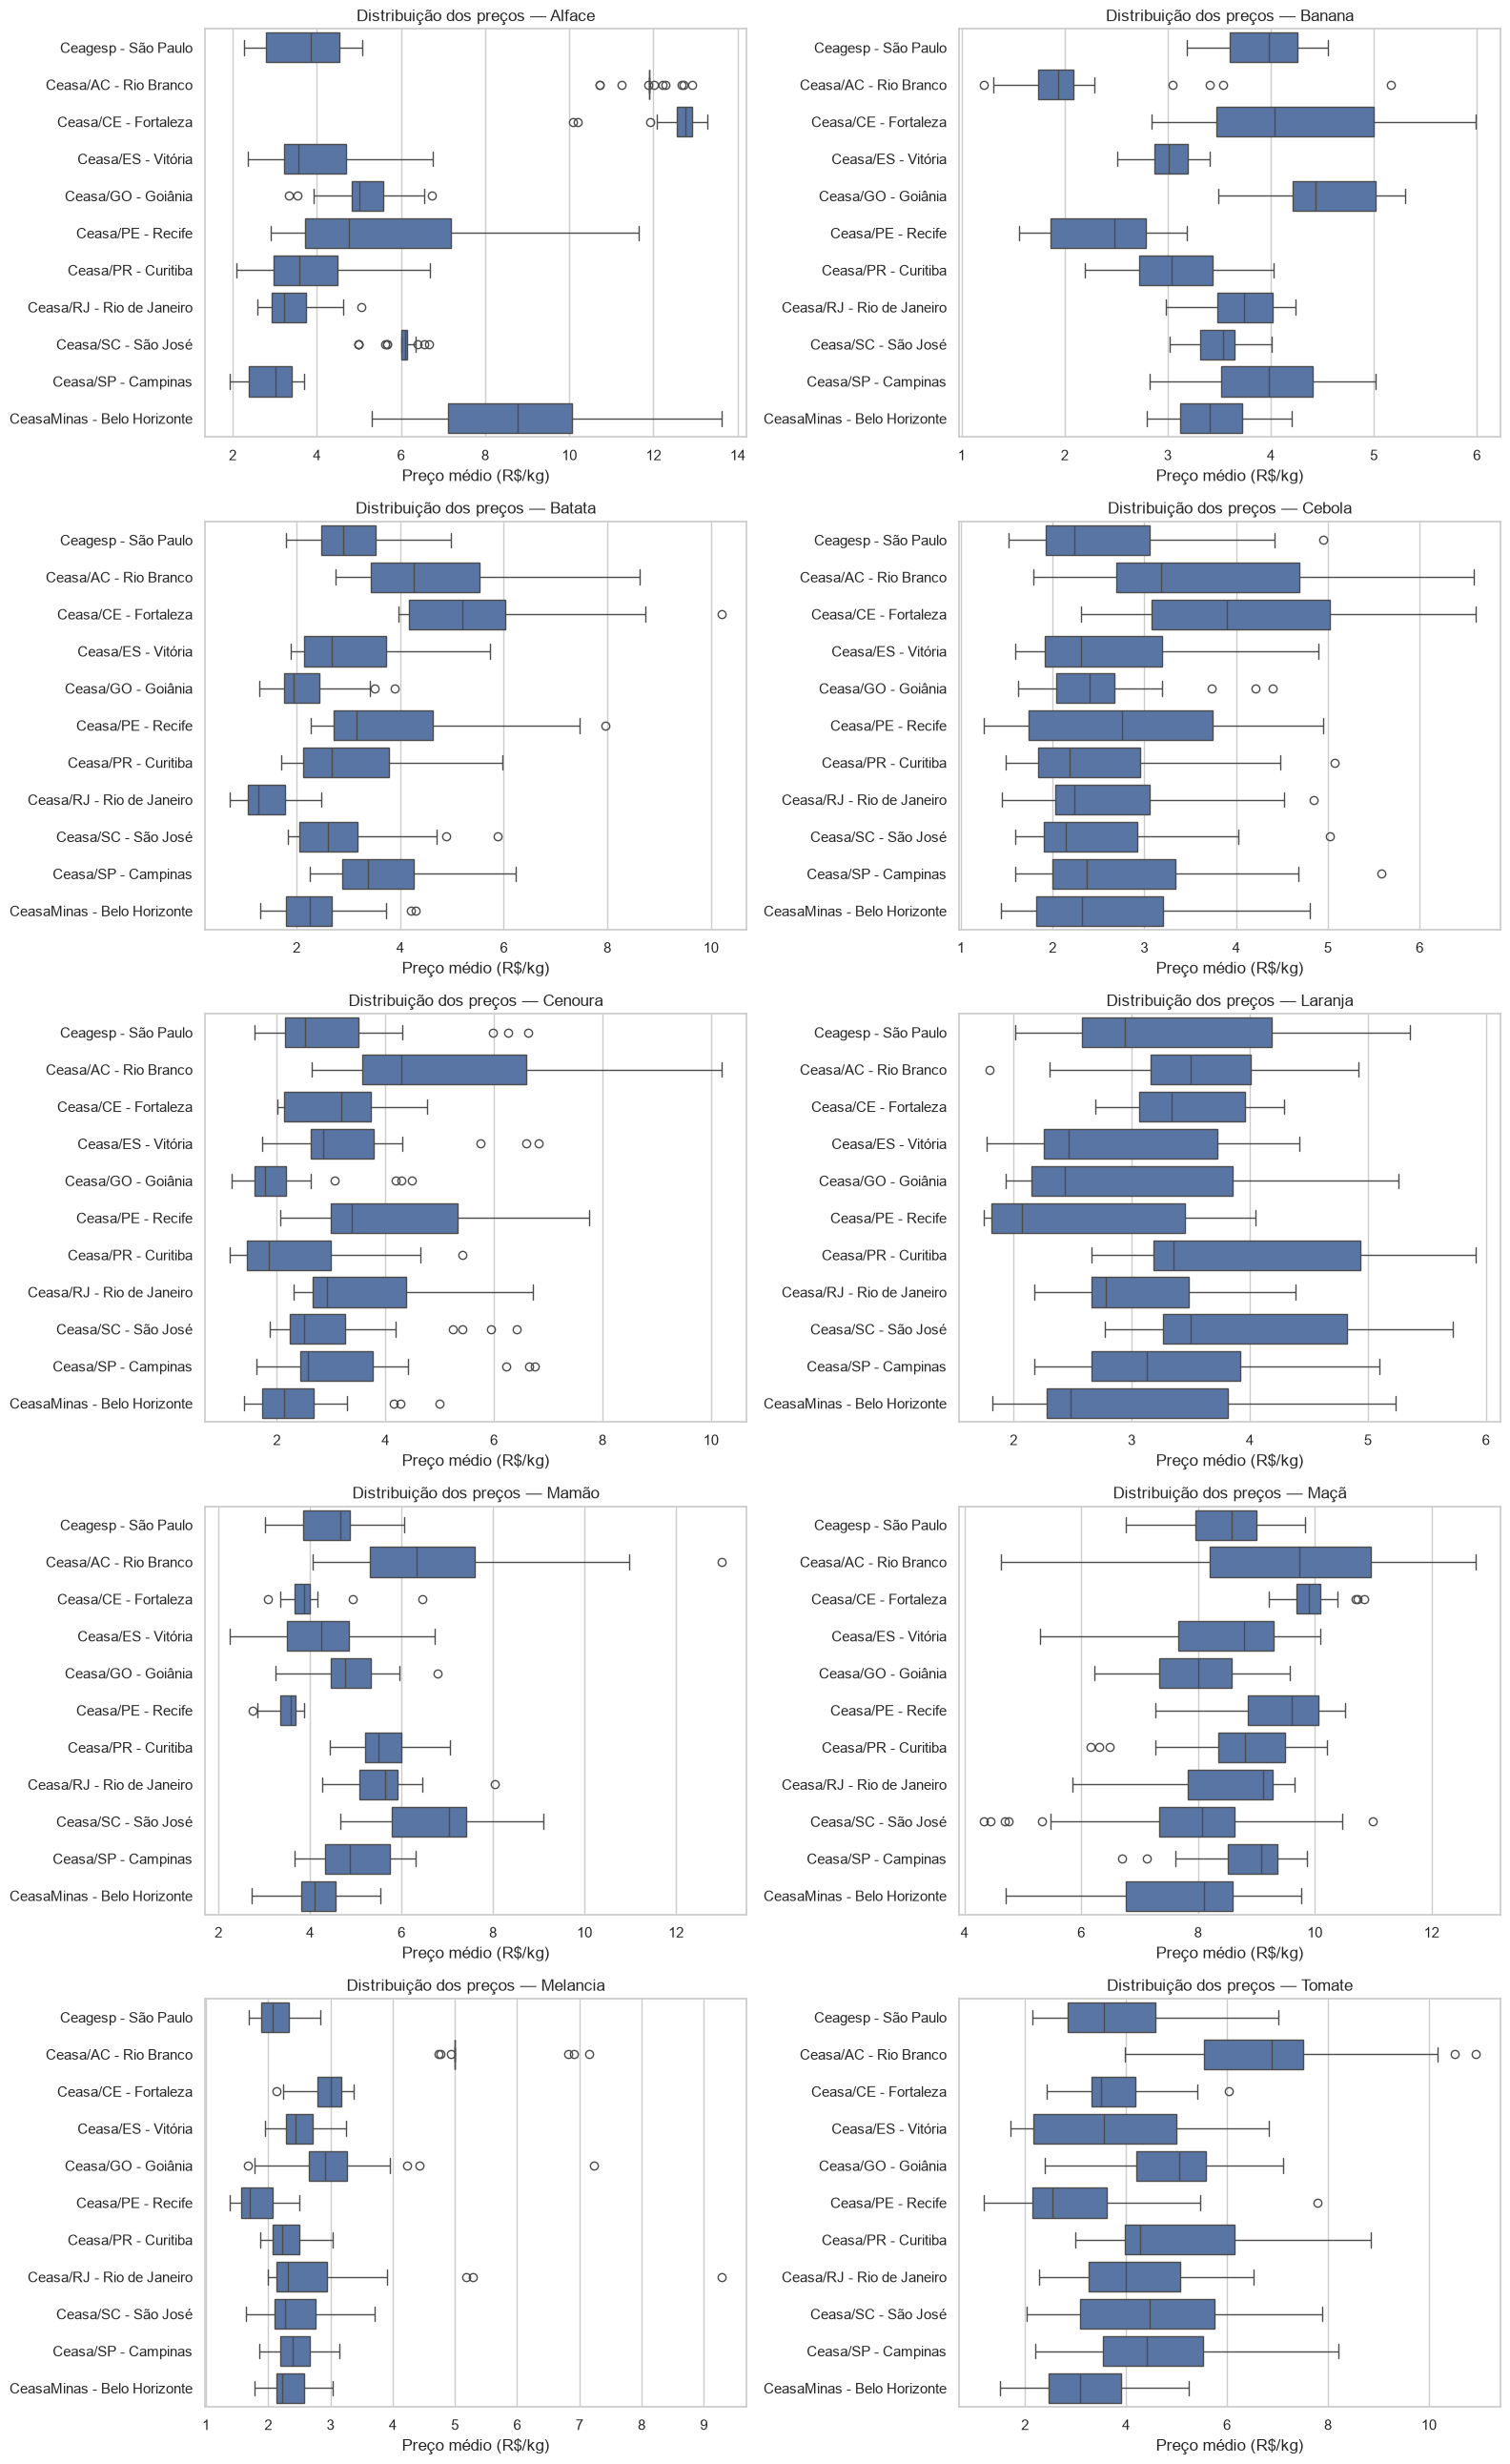

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ordem_produtos = sorted(df_modelagem["produto"].unique())
ordem_ceasas = sorted(df_modelagem["ceasa"].unique())

fig, axes = plt.subplots(5, 2, figsize=(16, 26))
axes = axes.flatten()

for ax, produto in zip(axes, ordem_produtos):
    dados_produto = df_modelagem.loc[
        df_modelagem["produto"] == produto
    ].dropna(subset=["preco"])

    sns.boxplot(
        data=dados_produto,
        x="preco",
        y="ceasa",
        order=ordem_ceasas,
        ax=ax
    )
    ax.set_title(f"Distribuição dos preços — {produto}")
    ax.set_xlabel("Preço médio (R$/kg)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Leitura dos resultados:** os boxplots permitem comparar mediana, dispersão e possíveis valores extremos dentro de cada produto. Como os produtos possuem faixas de preço distintas, a comparação deve ser feita principalmente entre CEASAs para o mesmo produto, e não apenas pela posição absoluta dos boxplots.


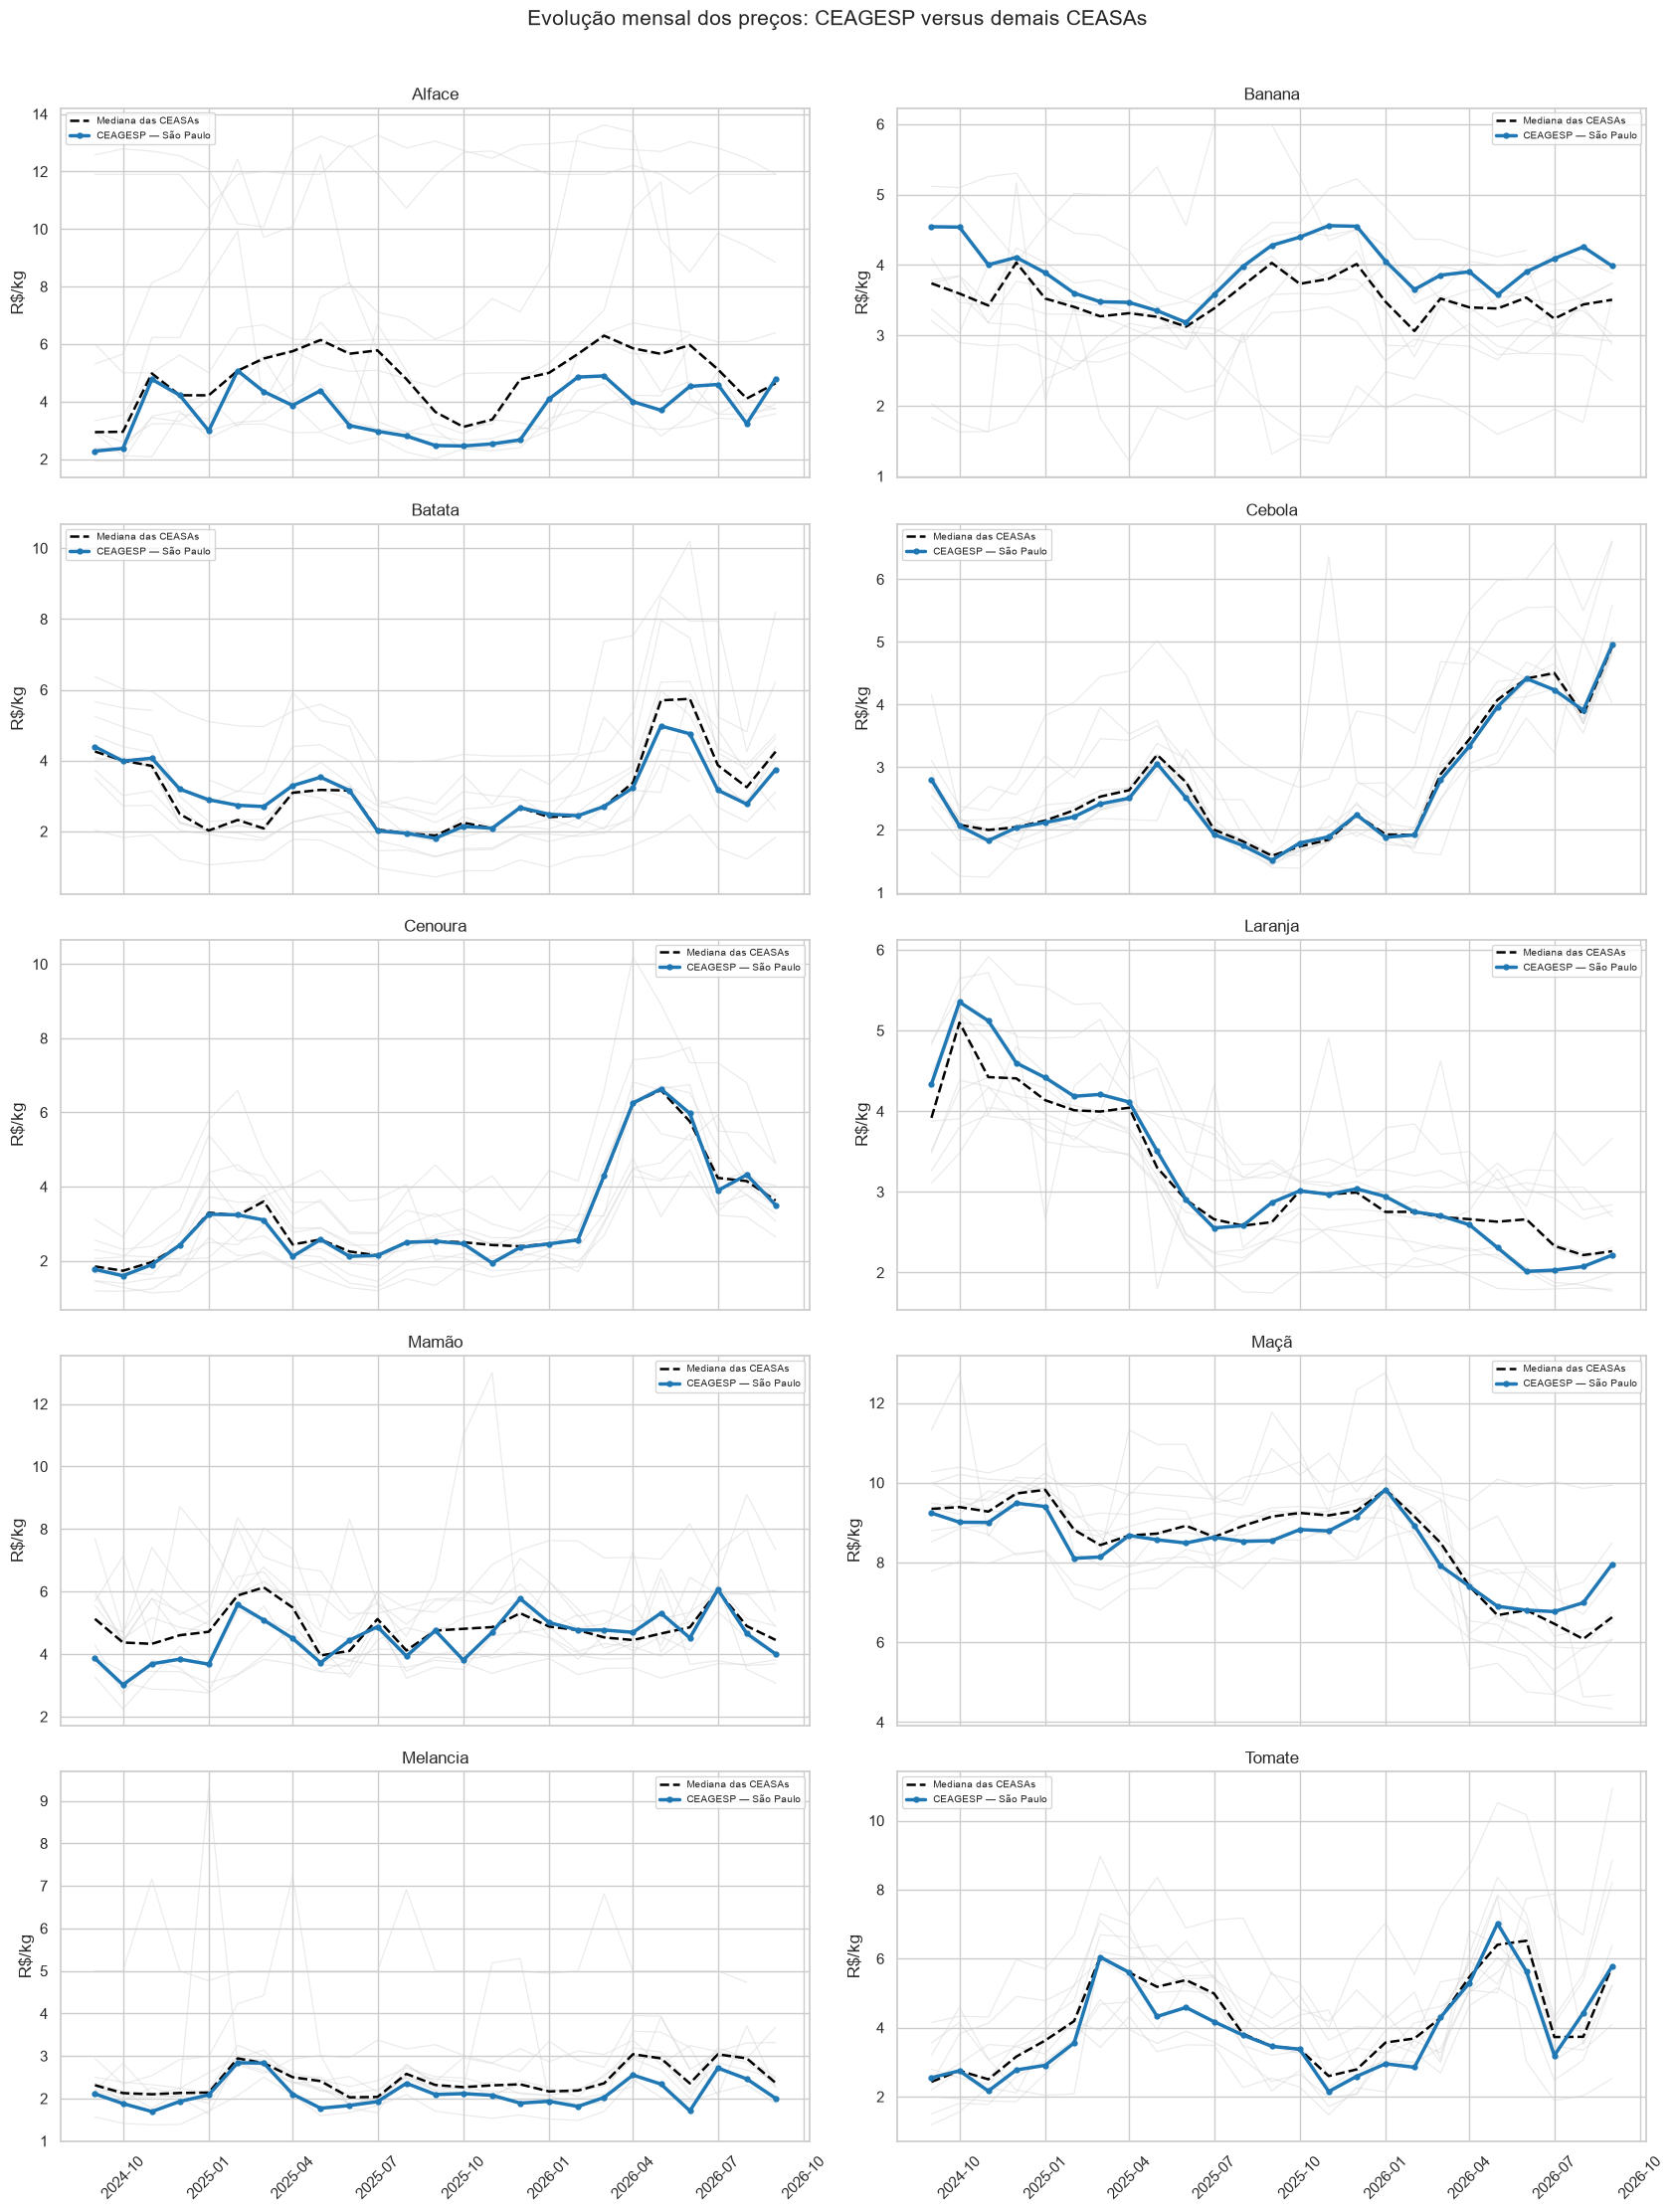

In [11]:
# Evolução mensal: mercado de referência versus CEAGESP
ceagesp_nome = "Ceagesp - São Paulo"

fig, axes = plt.subplots(5, 2, figsize=(17, 22), sharex=True)
axes = axes.flatten()

for ax, produto in zip(axes, ordem_produtos):
    dados_produto = df_modelagem[
        df_modelagem["produto"] == produto
    ].sort_values(["ceasa", "data_ref"])

    # Demais CEASAs: cinza claro, linhas finas.
    # Não remover NaN: as lacunas devem interromper as linhas.
    outras = dados_produto[dados_produto["ceasa"] != ceagesp_nome]

    for ceasa, serie in outras.groupby("ceasa", sort=False):
        ax.plot(
            serie["data_ref"],
            serie["preco"],
            color="lightgray",
            alpha=0.45,
            linewidth=0.9
        )

    # Mediana mensal entre as CEASAs disponíveis
    mediana_mercado = (
        dados_produto.groupby("data_ref")["preco"]
        .median()
        .sort_index()
    )
    ax.plot(
        mediana_mercado.index,
        mediana_mercado.values,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="Mediana das CEASAs"
    )

    # CEAGESP em destaque; NaN permanece como quebra na série
    sp = dados_produto[dados_produto["ceasa"] == ceagesp_nome]
    ax.plot(
        sp["data_ref"],
        sp["preco"],
        color="tab:blue",
        linewidth=2.5,
        marker="o",
        markersize=3.5,
        label="CEAGESP — São Paulo"
    )

    ax.set_title(produto)
    ax.set_ylabel("R$/kg")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=7, loc="best")

fig.suptitle(
    "Evolução mensal dos preços: CEAGESP versus demais CEASAs",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()


**Leitura dos resultados:** em cada painel, as linhas cinza representam as demais CEASAs, a linha preta tracejada representa a mediana mensal entre as CEASAs com preço disponível e a linha azul destaca a CEAGESP. A comparação ajuda a identificar períodos em que São Paulo acompanha ou se distancia do comportamento central observado. A mediana mensal pode variar no número de CEASAs participantes quando há valores ausentes.


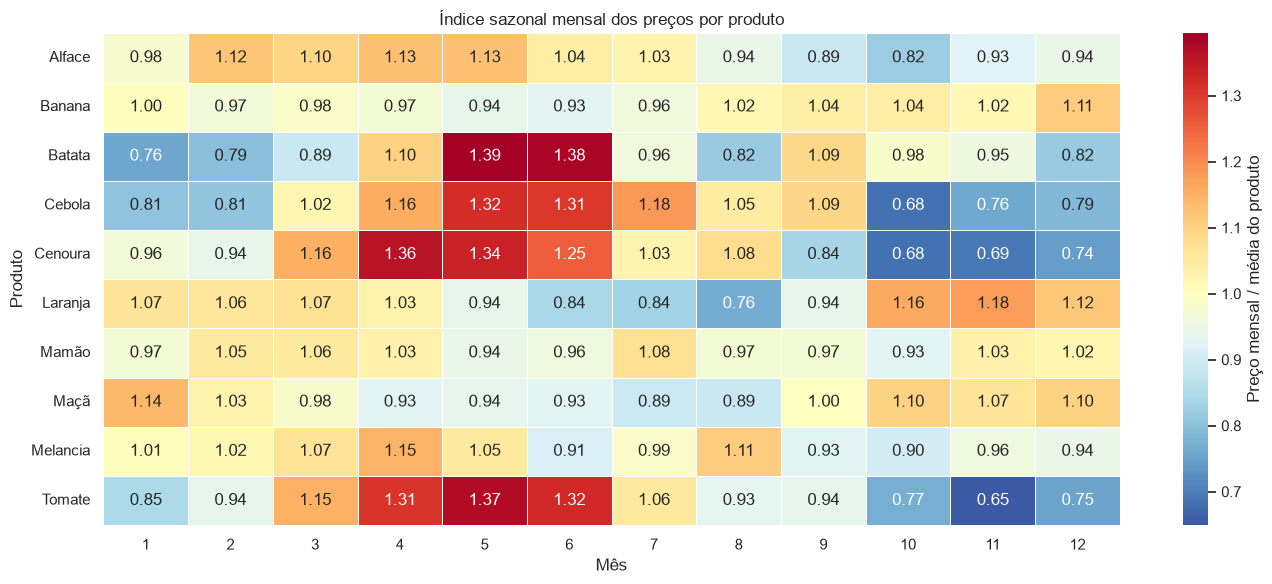

In [12]:
# Sazonalidade: média mensal relativa à média de cada produto
media_mensal = (
    df_modelagem.groupby(["produto", "mes"])["preco"]
    .mean()
    .unstack("mes")
)

media_geral_produto = (
    df_modelagem.groupby("produto")["preco"].mean()
)

indice_sazonal = media_mensal.div(media_geral_produto, axis=0)

# Garantir ordenação cronológica dos meses
indice_sazonal = indice_sazonal.reindex(
    index=ordem_produtos,
    columns=range(1, 13)
)

plt.figure(figsize=(14, 6))
sns.heatmap(
    indice_sazonal,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=1,
    linewidths=0.5,
    cbar_kws={"label": "Preço mensal / média do produto"}
)
plt.title("Índice sazonal mensal dos preços por produto")
plt.xlabel("Mês")
plt.ylabel("Produto")
plt.tight_layout()
plt.show()


**Leitura dos resultados:** valores acima de 1 indicam que a média daquele mês ficou acima da média geral do produto; valores abaixo de 1 indicam média inferior. O heatmap é uma exploração inicial de sazonalidade. Como a série cobre somente 25 meses, há pouco mais de dois ciclos anuais; portanto, padrões sazonais devem ser tratados como indícios, não como regularidades consolidadas.


## 10. Contexto complementar: participação da CEAGESP nas quantidades

As abas `Quantidade-*` da planilha apresentam apenas três referências (setembro/2025, agosto/2026 e setembro/2026). A célula abaixo calcula a participação da CEAGESP no total das CEASAs listadas em cada aba, quando os dados estão disponíveis.

**Limitação:** esse recorte curto serve apenas como contexto de abastecimento. Não será incorporado ao modelo de previsão de preços de 25 meses.


In [13]:
# Participação da CEAGESP nas quantidades comercializadas
# Contexto exploratório — não será utilizada como feature do modelo

quantidade_registros = []

for produto in ordem_produtos:
    aba_q = pd.read_excel(
        CAMINHO_XLSX,
        sheet_name=f"Quantidade-{produto}",
        header=None
    )

    # Cabeçalho com os três meses na linha 4
    cabecalho = aba_q.iloc[3, 1:4].tolist()

    dados_q = aba_q.iloc[4:, :4].copy()
    dados_q.columns = ["ceasa", *cabecalho]

    # Remover rodapés e linhas sem identificação
    dados_q = dados_q.dropna(subset=["ceasa"])
    dados_q["ceasa"] = dados_q["ceasa"].astype(str).str.strip()

    # Incluir CEAGESP e as demais CEASAs
    dados_q = dados_q[
        dados_q["ceasa"].str.contains(
            r"CEAGESP|CEASA",
            case=False,
            na=False,
            regex=True
        )
    ]

    # Converter quantidades para valores numéricos
    colunas_meses = list(dados_q.columns[1:])

    for coluna in colunas_meses:
        dados_q[coluna] = pd.to_numeric(
            dados_q[coluna],
            errors="coerce"
        )

    # Localizar a CEAGESP
    linha_sp = dados_q[
        dados_q["ceasa"].str.contains(
            "CEAGESP",
            case=False,
            na=False
        )
    ]

    if linha_sp.empty:
        print(f"Aviso: CEAGESP não encontrada para {produto}")
        continue

    for coluna in colunas_meses:
        total = dados_q[coluna].sum(min_count=1)
        valor_sp = linha_sp.iloc[0][coluna]

        participacao = (
            valor_sp / total * 100
            if pd.notna(total)
            and total != 0
            and pd.notna(valor_sp)
            else float("nan")
        )

        quantidade_registros.append({
            "produto": produto,
            "referencia": str(coluna),
            "quantidade_ceagesp_kg": valor_sp,
            "total_ceasas_kg": total,
            "participacao_ceagesp_pct": participacao
        })

participacao_ceagesp = pd.DataFrame(quantidade_registros)

display(participacao_ceagesp.round(2))

,produto,referencia,quantidade_ceagesp_kg,total_ceasas_kg,participacao_ceagesp_pct
0,Alface,Setembro de 2025,2277348.0,4561032.0,49.93
1,Alface,Agosto de 2026,2032813.0,4222485.0,48.14
2,Alface,Setembro de 2026,1838391.0,4048037.0,45.41
3,Banana,Setembro de 2025,5056548.0,44637587.0,11.33
4,Banana,Agosto de 2026,5589134.0,40672198.0,13.74
5,Banana,Setembro de 2026,5355803.0,49540503.0,10.81
6,Batata,Setembro de 2025,25339830.0,100585133.0,25.19
7,Batata,Agosto de 2026,22823900.0,86340624.0,26.43
8,Batata,Setembro de 2026,22805295.0,86520019.0,26.36
9,Cebola,Setembro de 2025,10156460.0,39945849.0,25.43


## 11. Modelagem supervisionada principal — painel nacional CONAB

A modelagem principal utiliza os preços mensais dos dez produtos em 11 CEASAs, sem incorporar variáveis meteorológicas. O alvo é `preco` (R$/kg), e os atributos históricos são calculados separadamente para cada combinação `produto × ceasa`.

Serão comparados o Baseline (Lag 1), Ridge Regression e Random Forest. A sazonalidade será representada por `mes_sin` e `mes_cos`, sem utilizar `ano` como preditor.

A separação será cronológica: treinamento até junho de 2026 e teste de julho a setembro de 2026. A escolha de hiperparâmetros ocorrerá somente em uma validação interna do conjunto de treinamento. O teste final permanecerá intocado até a etapa de avaliação final.

As métricas serão apresentadas no conjunto geral e por CEASA. A CEAGESP-SP também será destacada para conectar a análise nacional ao piloto territorial da NutriRota.

In [14]:
# 9.1. Engenharia de atributos — painel nacional CONAB

import numpy as np

base_conab_modelagem = df_modelagem.copy()
base_conab_modelagem["data_ref"] = pd.to_datetime(base_conab_modelagem["data_ref"])
base_conab_modelagem = base_conab_modelagem.sort_values(
    ["produto", "ceasa", "data_ref"]
).copy()

# Sazonalidade cíclica
base_conab_modelagem["mes"] = base_conab_modelagem["data_ref"].dt.month
base_conab_modelagem["mes_sin"] = np.sin(
    2 * np.pi * base_conab_modelagem["mes"] / 12
)
base_conab_modelagem["mes_cos"] = np.cos(
    2 * np.pi * base_conab_modelagem["mes"] / 12
)

# Lags e média móvel calculados dentro de cada série produto × CEASA
grupo_nacional = base_conab_modelagem.groupby(
    ["produto", "ceasa"]
)["preco"]

for lag in [1, 2, 3]:
    base_conab_modelagem[f"lag_{lag}"] = grupo_nacional.shift(lag)

base_conab_modelagem["media_movel_3m"] = grupo_nacional.transform(
    lambda serie: serie.shift(1).rolling(3).mean()
)

# Remover apenas observações sem alvo ou sem histórico suficiente
colunas_historico_nacional = [
    "lag_1", "lag_2", "lag_3", "media_movel_3m",
    "mes_sin", "mes_cos"
]
base_modelagem_nacional = base_conab_modelagem.dropna(
    subset=["preco"] + colunas_historico_nacional
).copy()

print("Dimensão após engenharia de atributos:", base_modelagem_nacional.shape)
print("Produtos:", base_modelagem_nacional["produto"].nunique())
print("CEASAs:", base_modelagem_nacional["ceasa"].nunique())
print("\nRegistros por CEASA:")
display(base_modelagem_nacional.groupby("ceasa").size().rename("registros").to_frame())
print("\nPeríodo:", base_modelagem_nacional["data_ref"].min(),
      "até", base_modelagem_nacional["data_ref"].max())
print("\nAusentes nos atributos e alvo:")
display(base_modelagem_nacional[
    ["preco"] + colunas_historico_nacional
].isna().sum().to_frame("ausentes"))

Dimensão após engenharia de atributos: (2385, 14)
Produtos: 10
CEASAs: 11

Registros por CEASA:


,registros
ceasa,
Ceagesp - São Paulo,220
Ceasa/AC - Rio Branco,215
Ceasa/CE - Fortaleza,220
Ceasa/ES - Vitória,220
Ceasa/GO - Goiânia,190
Ceasa/PE - Recife,220
Ceasa/PR - Curitiba,220
Ceasa/RJ - Rio de Janeiro,220
Ceasa/SC - São José,220



Período: 2024-12-01 00:00:00 até 2026-09-01 00:00:00

Ausentes nos atributos e alvo:


,ausentes
preco,0
lag_1,0
lag_2,0
lag_3,0
media_movel_3m,0
mes_sin,0
mes_cos,0


### 11.2. Separação temporal e validação cruzada — painel nacional

O teste final compreende julho a setembro de 2026 e permanece isolado de todas as etapas de seleção e ajuste. O período anterior é dividido em treinamento e avaliação temporal complementar: treinamento interno até março de 2026 e holdout de abril a junho de 2026.

A seleção das configurações de Ridge e Random Forest é realizada por validação cruzada temporal (`TimeSeriesSplit`) aplicada exclusivamente ao treinamento interno. A divisão é feita por mês, mantendo todas as observações de produtos e CEASAs de uma mesma referência mensal no mesmo fold. São utilizados três folds expansivos, com três meses em cada janela de validação. O holdout de abril a junho funciona como avaliação temporal complementar, sem ser utilizado para selecionar hiperparâmetros.

In [15]:
# Separação cronológica — painel nacional

data_inicio_teste_nacional = pd.Timestamp("2026-07-01")
data_inicio_validacao_nacional = pd.Timestamp("2026-04-01")

treino_nacional = base_modelagem_nacional[
    base_modelagem_nacional["data_ref"] < data_inicio_teste_nacional
].copy()
teste_nacional = base_modelagem_nacional[
    base_modelagem_nacional["data_ref"] >= data_inicio_teste_nacional
].copy()

treino_interno_nacional = treino_nacional[
    treino_nacional["data_ref"] < data_inicio_validacao_nacional
].copy()
validacao_nacional = treino_nacional[
    treino_nacional["data_ref"] >= data_inicio_validacao_nacional
].copy()

print("Treino interno:", len(treino_interno_nacional))
print("Validação:", len(validacao_nacional))
print("Treino completo:", len(treino_nacional))
print("Teste final reservado:", len(teste_nacional))

print("\nPeríodos:")
print("Treino interno:",
      treino_interno_nacional["data_ref"].min(),
      "até", treino_interno_nacional["data_ref"].max())
print("Validação:",
      validacao_nacional["data_ref"].min(),
      "até", validacao_nacional["data_ref"].max())
print("Teste:",
      teste_nacional["data_ref"].min(),
      "até", teste_nacional["data_ref"].max())

print("\nObservações no teste por CEASA:")
display(teste_nacional.groupby("ceasa").size().rename("registros").to_frame())

# Definição das features
features_nacionais = [
    "lag_1", "lag_2", "lag_3", "media_movel_3m",
    "mes_sin", "mes_cos", "produto", "ceasa"
]
alvo_nacional = "preco"

X_treino_interno_nacional = treino_interno_nacional[features_nacionais]
X_validacao_nacional = validacao_nacional[features_nacionais]
y_treino_interno_nacional = treino_interno_nacional[alvo_nacional]
y_validacao_nacional = validacao_nacional[alvo_nacional]

Treino interno: 1756
Validação: 330
Treino completo: 2086
Teste final reservado: 299

Períodos:
Treino interno: 2024-12-01 00:00:00 até 2026-03-01 00:00:00
Validação: 2026-04-01 00:00:00 até 2026-06-01 00:00:00
Teste: 2026-07-01 00:00:00 até 2026-09-01 00:00:00

Observações no teste por CEASA:


,registros
ceasa,
Ceagesp - São Paulo,30
Ceasa/AC - Rio Branco,29
Ceasa/CE - Fortaleza,30
Ceasa/ES - Vitória,30
Ceasa/PE - Recife,30
Ceasa/PR - Curitiba,30
Ceasa/RJ - Rio de Janeiro,30
Ceasa/SC - São José,30
Ceasa/SP - Campinas,30


### 11.3. Modelos e seleção de hiperparâmetros — painel nacional

Os atributos numéricos serão padronizados no Ridge e mantidos na escala original no Random Forest. `produto` e `ceasa` serão codificados por One-Hot Encoding dentro dos pipelines.

As configurações serão comparadas pela média do MAE em três folds de validação cruzada temporal, executados exclusivamente no treinamento interno. Em cada fold, o pré-processamento é ajustado novamente dentro do pipeline, somente com os dados daquele fold de treinamento. O Baseline utiliza diretamente `lag_1` e também será avaliado nos mesmos períodos de validação.

In [16]:
# Funções auxiliares compartilhadas pelos experimentos nacional e climático

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def calcular_metricas(y_real, y_pred):
    """Calcula métricas de regressão, ignorando zeros apenas no denominador do MAPE."""
    y_real = np.asarray(y_real, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()

    mascara_validos = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real = y_real[mascara_validos]
    y_pred = y_pred[mascara_validos]

    if len(y_real) == 0:
        raise ValueError("Não há observações válidas para calcular as métricas.")

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mascara_mape = y_real != 0
    mape = (
        np.mean(np.abs((y_real[mascara_mape] - y_pred[mascara_mape]) /
                       y_real[mascara_mape])) * 100
        if mascara_mape.any() else np.nan
    )
    r2 = r2_score(y_real, y_pred) if len(y_real) >= 2 else np.nan

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape, "R²": r2}


def criar_pipeline_nacional(
    familia,
    alpha=1.0,
    max_depth=None,
    min_samples_leaf=2
):
    """Cria pipeline nacional com pré-processamento ajustado dentro de cada fold."""
    numericas = [
        "lag_1", "lag_2", "lag_3", "media_movel_3m",
        "mes_sin", "mes_cos"
    ]
    categoricas = ["produto", "ceasa"]

    if familia == "Ridge":
        preprocessador = ColumnTransformer([
            ("numericas", StandardScaler(), numericas),
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
        ])
        estimador = Ridge(alpha=alpha)

    elif familia == "Random Forest":
        preprocessador = ColumnTransformer([
            ("numericas", "passthrough", numericas),
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
        ])
        estimador = RandomForestRegressor(
            n_estimators=300,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=42,
            n_jobs=-1
        )
    else:
        raise ValueError(
            "Família não reconhecida. Use 'Ridge' ou 'Random Forest'."
        )

    return Pipeline([
        ("preprocessamento", preprocessador),
        ("modelo", estimador)
    ])


In [17]:
# Validação cruzada temporal e seleção de hiperparâmetros — painel nacional

from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# A divisão é feita por mês, não por linha, para manter todas as CEASAs
# e produtos de um mesmo mês no mesmo fold.
meses_treino_cv = np.array(
    sorted(treino_interno_nacional["data_ref"].drop_duplicates())
)

N_SPLITS = 3
MESES_VALIDACAO_FOLD = 3

if len(meses_treino_cv) < N_SPLITS + 1:
    raise ValueError("Histórico insuficiente para a validação cruzada temporal.")

tscv_nacional = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=MESES_VALIDACAO_FOLD
)

def gerar_folds_por_mes(df, meses, splitter):
    """Gera índices de treino/validação mantendo cada mês inteiro no mesmo fold."""
    for idx_treino_meses, idx_validacao_meses in splitter.split(meses):
        meses_treino = meses[idx_treino_meses]
        meses_validacao = meses[idx_validacao_meses]

        mascara_treino = df["data_ref"].isin(meses_treino)
        mascara_validacao = df["data_ref"].isin(meses_validacao)

        yield (
            df.index[mascara_treino],
            df.index[mascara_validacao],
            meses_treino,
            meses_validacao
        )

folds_nacionais = list(
    gerar_folds_por_mes(treino_interno_nacional, meses_treino_cv, tscv_nacional)
)

print(f"Validação cruzada temporal: {N_SPLITS} folds")
for i, (_, _, meses_tr, meses_val) in enumerate(folds_nacionais, start=1):
    print(
        f"Fold {i}: treino {pd.Timestamp(meses_tr[0]).strftime('%m/%Y')} a "
        f"{pd.Timestamp(meses_tr[-1]).strftime('%m/%Y')} | "
        f"validação {pd.Timestamp(meses_val[0]).strftime('%m/%Y')} a "
        f"{pd.Timestamp(meses_val[-1]).strftime('%m/%Y')}"
    )

# Grade de configurações avaliada exclusivamente nos folds temporais.
candidatos_nacionais = []
for alpha in [0.1, 1.0, 10.0, 50.0]:
    candidatos_nacionais.append(
        ("Ridge", {"alpha": alpha}, criar_pipeline_nacional("Ridge", alpha=alpha))
    )

for profundidade in [None, 5, 10]:
    for folha in [2, 4]:
        candidatos_nacionais.append((
            "Random Forest",
            {"max_depth": profundidade, "min_samples_leaf": folha},
            criar_pipeline_nacional(
                "Random Forest",
                max_depth=profundidade,
                min_samples_leaf=folha
            )
        ))

linhas_cv_nacional = []
metricas_por_candidato = []

for familia, parametros, modelo_base in candidatos_nacionais:
    for numero_fold, (idx_tr, idx_val, _, _) in enumerate(folds_nacionais, start=1):
        dados_tr = treino_interno_nacional.loc[idx_tr]
        dados_val = treino_interno_nacional.loc[idx_val]

        X_tr = dados_tr[features_nacionais]
        y_tr = dados_tr[alvo_nacional]
        X_val = dados_val[features_nacionais]
        y_val = dados_val[alvo_nacional]

        modelo_fold = clone(modelo_base)
        modelo_fold.fit(X_tr, y_tr)
        pred = modelo_fold.predict(X_val)
        metricas = calcular_metricas(y_val, pred)

        linha = {
            "Modelo": familia,
            "Hiperparâmetros": str(parametros),
            "Fold": numero_fold,
            "n_treino": len(dados_tr),
            "n_validacao": len(dados_val),
            **metricas
        }
        linhas_cv_nacional.append(linha)
        metricas_por_candidato.append((familia, parametros, numero_fold, metricas))

df_folds_nacional = pd.DataFrame(linhas_cv_nacional)

# Média e desvio-padrão entre folds para cada configuração.
df_resumo_cv_nacional = (
    df_folds_nacional
    .groupby(["Modelo", "Hiperparâmetros"])
    .agg(
        MAE_medio=("MAE", "mean"),
        MAE_dp=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        MAPE_medio=("MAPE (%)", "mean"),
        R2_medio=("R²", "mean")
    )
    .reset_index()
    .sort_values("MAE_medio")
    .reset_index(drop=True)
)

display(df_folds_nacional.round(4))
display(df_resumo_cv_nacional.round(4))

# Seleção da configuração de cada família pela média do MAE nos folds.
modelos_escolhidos_nacional = {}
for familia in ["Ridge", "Random Forest"]:
    opcoes = df_resumo_cv_nacional[
        df_resumo_cv_nacional["Modelo"] == familia
    ]
    melhor = opcoes.sort_values("MAE_medio").iloc[0]
    import ast
    parametros = ast.literal_eval(melhor["Hiperparâmetros"])
    modelo_selecionado = criar_pipeline_nacional(familia, **parametros)

    # Ajuste no treinamento interno completo para avaliação complementar
    # no holdout temporal de abril a junho de 2026.
    modelo_selecionado.fit(
        X_treino_interno_nacional,
        y_treino_interno_nacional
    )

    modelos_escolhidos_nacional[familia] = {
        "parametros": parametros,
        "modelo_validacao": modelo_selecionado,
        "mae_cv_medio": melhor["MAE_medio"],
        "mae_cv_dp": melhor["MAE_dp"]
    }

print("\nConfigurações selecionadas pela média do MAE na validação cruzada:")
for familia, info in modelos_escolhidos_nacional.items():
    print(
        f"{familia}: {info['parametros']} | "
        f"MAE CV médio = {info['mae_cv_medio']:.4f}"
    )

# Avaliação complementar no holdout de abril a junho de 2026.
# Este período permanece dentro do conjunto de treinamento e não substitui
# a validação cruzada usada para selecionar hiperparâmetros.
resultados_validacao_nacional = [{
    "Modelo": "Baseline - Lag 1",
    **calcular_metricas(
        y_validacao_nacional,
        validacao_nacional["lag_1"].to_numpy()
    )
}]

for familia, info in modelos_escolhidos_nacional.items():
    pred = info["modelo_validacao"].predict(X_validacao_nacional)
    resultados_validacao_nacional.append({
        "Modelo": familia,
        "Hiperparâmetros (seleção CV)": str(info["parametros"]),
        **calcular_metricas(y_validacao_nacional, pred)
    })

df_resultados_validacao_nacional = pd.DataFrame(resultados_validacao_nacional)
print("Avaliação temporal complementar — abril a junho de 2026:")
display(df_resultados_validacao_nacional.round(4))


Validação cruzada temporal: 3 folds
Fold 1: treino 12/2024 a 06/2025 | validação 07/2025 a 09/2025
Fold 2: treino 12/2024 a 09/2025 | validação 10/2025 a 12/2025
Fold 3: treino 12/2024 a 12/2025 | validação 01/2026 a 03/2026


,Modelo,Hiperparâmetros,Fold,n_treino,n_validacao,MAE,RMSE,MAPE (%),R²
0,Ridge,{'alpha': 0.1},1,766,330,0.6033,0.7763,17.3235,0.9010
1,Ridge,{'alpha': 0.1},2,1096,330,0.4636,0.7821,13.4901,0.9100
2,Ridge,{'alpha': 0.1},3,1426,330,0.5381,0.7692,14.1893,0.9106
3,Ridge,{'alpha': 1.0},1,766,330,0.6035,0.7766,17.3248,0.9009
4,Ridge,{'alpha': 1.0},2,1096,330,0.4625,0.7817,13.4497,0.9101
5,Ridge,{'alpha': 1.0},3,1426,330,0.5384,0.7693,14.2001,0.9105
6,Ridge,{'alpha': 10.0},1,766,330,0.6049,0.7787,17.3413,0.9003
7,Ridge,{'alpha': 10.0},2,1096,330,0.4550,0.7798,13.1611,0.9106
8,Ridge,{'alpha': 10.0},3,1426,330,0.5421,0.7722,14.3149,0.9099
9,Ridge,{'alpha': 50.0},1,766,330,0.6063,0.7818,17.4429,0.8996


,Modelo,Hiperparâmetros,MAE_medio,MAE_dp,RMSE_medio,MAPE_medio,R2_medio
0,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 4}",0.4939,0.0666,0.7671,14.5150,0.9093
1,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 2}",0.4961,0.0668,0.7724,14.5621,0.9080
2,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 4}",0.5116,0.0578,0.7760,15.1564,0.9072
3,Random Forest,"{'max_depth': None, 'min_samples_leaf': 4}",0.5138,0.0582,0.7766,15.2577,0.9071
4,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 2}",0.5158,0.0577,0.7848,15.2255,0.9051
5,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2}",0.5187,0.0576,0.7867,15.3717,0.9046
6,Ridge,{'alpha': 10.0},0.5340,0.0753,0.7769,14.9391,0.9069
7,Ridge,{'alpha': 1.0},0.5348,0.0706,0.7759,14.9915,0.9072
8,Ridge,{'alpha': 0.1},0.5350,0.0699,0.7759,15.0010,0.9072
9,Ridge,{'alpha': 50.0},0.5381,0.0789,0.7848,14.9897,0.9051



Configurações selecionadas pela média do MAE na validação cruzada:
Ridge: {'alpha': 10.0} | MAE CV médio = 0.5340
Random Forest: {'max_depth': 5, 'min_samples_leaf': 4} | MAE CV médio = 0.4939
Avaliação temporal complementar — abril a junho de 2026:


,Modelo,MAE,RMSE,MAPE (%),R²,Hiperparâmetros (seleção CV)
0,Baseline - Lag 1,0.7640,1.2008,15.7549,0.7175,NaN
1,Ridge,0.8730,1.2635,17.3053,0.6872,{'alpha': 10.0}
2,Random Forest,0.8284,1.2397,16.3868,0.6988,"{'max_depth': 5, 'min_samples_leaf': 4}"


### 11.4. Diagnóstico da validação por CEASA

Além das métricas agregadas, os erros serão apresentados por CEASA. Esse recorte permite verificar se o desempenho geral é influenciado por diferenças entre os entrepostos e destacar a CEAGESP-SP.

Os resultados continuam sendo de validação, não de teste final.

In [18]:
# Métricas na validação por CEASA

predicoes_validacao_nacional = {
    "Baseline - Lag 1": validacao_nacional["lag_1"].to_numpy()
}
for familia, info in modelos_escolhidos_nacional.items():
    predicoes_validacao_nacional[familia] = info["modelo_validacao"].predict(
        X_validacao_nacional
    )

resultados_ceasa_validacao = []
for ceasa, grupo in validacao_nacional.groupby("ceasa"):
    idx = grupo.index
    y_real = grupo["preco"].to_numpy()
    linha = {"CEASA": ceasa, "n": len(grupo)}
    for nome, pred_total in predicoes_validacao_nacional.items():
        pred_series = pd.Series(pred_total, index=validacao_nacional.index)
        linha[f"MAE — {nome}"] = mean_absolute_error(
            y_real, pred_series.loc[idx].to_numpy()
        )
    resultados_ceasa_validacao.append(linha)

df_mae_ceasa_validacao = pd.DataFrame(resultados_ceasa_validacao)
display(df_mae_ceasa_validacao.round(4))

print("\nDestaque — CEAGESP:")
display(
    df_mae_ceasa_validacao[
        df_mae_ceasa_validacao["CEASA"].str.contains("CEAGESP", case=False, na=False)
    ].round(4)
)

,CEASA,n,MAE — Baseline - Lag 1,MAE — Ridge,MAE — Random Forest
0,Ceagesp - São Paulo,30,0.6199,0.7280,0.6388
1,Ceasa/AC - Rio Branco,30,1.1669,1.2131,1.2022
2,Ceasa/CE - Fortaleza,30,0.6989,0.8406,0.8112
3,Ceasa/ES - Vitória,30,0.7505,0.8447,0.7657
4,Ceasa/GO - Goiânia,30,0.6604,0.6767,0.6677
5,Ceasa/PE - Recife,30,1.1298,1.2316,1.2470
6,Ceasa/PR - Curitiba,30,0.7280,0.8175,0.7510
7,Ceasa/RJ - Rio de Janeiro,30,0.6645,0.7847,0.7311
8,Ceasa/SC - São José,30,0.8074,0.9469,0.9108
9,Ceasa/SP - Campinas,30,0.5382,0.7700,0.6722



Destaque — CEAGESP:


,CEASA,n,MAE — Baseline - Lag 1,MAE — Ridge,MAE — Random Forest
0,Ceagesp - São Paulo,30,0.6199,0.728,0.6388


## 12. Experimento complementar — CEAGESP-SP + INMET A701

Este bloco mantém a análise climática separada da modelagem nacional. A estação A701 (Mirante de Santana) mede condições meteorológicas da capital paulista; por isso, suas variáveis serão utilizadas exclusivamente no recorte da CEAGESP-SP.

A comparação será feita entre modelos sem clima e com clima, mantendo os mesmos registros e utilizando somente variáveis meteorológicas defasadas em um mês.

In [19]:
# INTEGRAÇÃO DOS DADOS METEOROLÓGICOS — INMET A701
# São Paulo - Mirante de Santana

from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import numpy as np

# 1. Caminhos do projeto
RAIZ = Path.cwd().parent
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_PROCESSED = RAIZ / "data" / "processed"
PASTA_PROCESSED.mkdir(parents=True, exist_ok=True)

arquivos_zip = [
    PASTA_RAW / "INMET2024.zip",
    PASTA_RAW / "INMET2025.zip",
    PASTA_RAW / "INMET2026.zip"
]

# 2. Colunas necessárias
COL_DATA = "Data"
COL_HORA = "Hora UTC"
COL_PRECIP = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
COL_TEMP = "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)"
COL_UMIDADE = "UMIDADE RELATIVA DO AR, HORARIA (%)"

dados_horarios = []

# 3. Leitura dos arquivos da estação A701
for caminho_zip in arquivos_zip:

    if not caminho_zip.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho_zip}")

    print(f"Lendo {caminho_zip.name}...")

    with ZipFile(caminho_zip, "r") as zip_ref:

        arquivos_a701 = [
            nome for nome in zip_ref.namelist()
            if "A701" in Path(nome).name.upper()
            and nome.lower().endswith(".csv")
        ]

        if len(arquivos_a701) != 1:
            raise ValueError(
                f"Esperado um CSV A701 em {caminho_zip.name}, "
                f"encontrados: {len(arquivos_a701)}"
            )

        with zip_ref.open(arquivos_a701[0]) as arquivo:
            df = pd.read_csv(
                BytesIO(arquivo.read()),
                sep=";",
                decimal=",",
                encoding="latin1",
                skiprows=8
            )

    df.columns = df.columns.str.strip()
    df = df.loc[
        :, ~df.columns.str.contains(r"^Unnamed", na=False)
    ]

    colunas_necessarias = [
        COL_DATA, COL_HORA, COL_PRECIP, COL_TEMP, COL_UMIDADE
    ]

    faltantes = [
        coluna for coluna in colunas_necessarias
        if coluna not in df.columns
    ]

    if faltantes:
        raise ValueError(
            f"Colunas ausentes em {caminho_zip.name}: {faltantes}"
        )

    # 4. Conversão das variáveis meteorológicas
    for coluna in [COL_PRECIP, COL_TEMP, COL_UMIDADE]:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
        df[coluna] = df[coluna].replace([-9999, -9999.0], np.nan)

    # 5. Construção do timestamp em UTC
    data = pd.to_datetime(
        df[COL_DATA],
        format="%Y/%m/%d",
        errors="coerce"
    )

    hora_extraida = (
        df[COL_HORA]
        .astype(str)
        .str.extract(r"(\d{2})(\d{2})")
    )

    hora_formatada = (
        hora_extraida[0] + ":" + hora_extraida[1]
    )

    timestamp_utc = pd.to_datetime(
        data.dt.strftime("%Y-%m-%d") + " " + hora_formatada,
        errors="coerce"
    ).dt.tz_localize("UTC")

    # Conversão para o horário local de São Paulo
    df["data_hora"] = (
        timestamp_utc
        .dt.tz_convert("America/Sao_Paulo")
        .dt.tz_localize(None)
    )

    df = df.dropna(subset=["data_hora"])

    # 6. Padronização dos nomes
    df = df.rename(columns={
        COL_PRECIP: "precipitacao_mm",
        COL_TEMP: "temperatura_c",
        COL_UMIDADE: "umidade_relativa_pct"
    })

    df["estacao"] = "A701"
    df["municipio"] = "São Paulo"

    dados_horarios.append(
        df[[
            "data_hora",
            "estacao",
            "municipio",
            "precipitacao_mm",
            "temperatura_c",
            "umidade_relativa_pct"
        ]]
    )

# 7. Consolidação dos três anos
inmet_horario = pd.concat(
    dados_horarios,
    ignore_index=True
)

inmet_horario = (
    inmet_horario
    .sort_values("data_hora")
    .drop_duplicates(subset=["data_hora"])
    .reset_index(drop=True)
)

# Referência mensal no horário local
inmet_horario["data_ref"] = (
    inmet_horario["data_hora"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# 8. Agregação mensal
inmet_mensal = (
    inmet_horario
    .groupby("data_ref")
    .agg(
        temperatura_media_c=("temperatura_c", "mean"),
        temperatura_max_horaria_c=("temperatura_c", "max"),
        precipitacao_total_mm=(
            "precipitacao_mm",
            lambda s: s.sum(min_count=1)
        ),
        umidade_media_pct=("umidade_relativa_pct", "mean"),

        horas_temperatura=("temperatura_c", "count"),
        horas_precipitacao=("precipitacao_mm", "count"),
        horas_umidade=("umidade_relativa_pct", "count")
    )
)

# 9. Cobertura mensal de cada variável
inmet_mensal["horas_esperadas"] = (
    inmet_mensal.index.days_in_month * 24
)

inmet_mensal["cobertura_temperatura_pct"] = (
    inmet_mensal["horas_temperatura"]
    / inmet_mensal["horas_esperadas"] * 100
).round(2)

inmet_mensal["cobertura_precipitacao_pct"] = (
    inmet_mensal["horas_precipitacao"]
    / inmet_mensal["horas_esperadas"] * 100
).round(2)

inmet_mensal["cobertura_umidade_pct"] = (
    inmet_mensal["horas_umidade"]
    / inmet_mensal["horas_esperadas"] * 100
).round(2)

inmet_mensal = inmet_mensal.reset_index()

inmet_mensal["estacao"] = "A701"
inmet_mensal["municipio"] = "São Paulo"

# 10. Recorte do período do experimento:
# setembro/2024 a setembro/2026
periodo = pd.date_range(
    start="2024-09-01",
    end="2026-09-01",
    freq="MS"
)

inmet_mensal = (
    inmet_mensal
    .set_index("data_ref")
    .reindex(periodo)
    .rename_axis("data_ref")
    .reset_index()
)

inmet_mensal["estacao"] = "A701"
inmet_mensal["municipio"] = "São Paulo"

# 11. Exportação dos dados processados
arquivo_horario = PASTA_PROCESSED / "inmet_sp_horario.csv"
arquivo_mensal = PASTA_PROCESSED / "inmet_sp_mensal.csv"

inmet_horario.to_csv(
    arquivo_horario,
    index=False,
    encoding="utf-8-sig"
)

inmet_mensal.to_csv(
    arquivo_mensal,
    index=False,
    encoding="utf-8-sig"
)

# 12. Relatório de validação
print("\n===== INTEGRAÇÃO INMET CONCLUÍDA =====")

print(f"Registros horários: {len(inmet_horario)}")
print(f"Meses no período analisado: {len(inmet_mensal)}")
print(
    "Período disponível:",
    inmet_horario["data_hora"].min(),
    "até",
    inmet_horario["data_hora"].max()
)

print("\nCobertura mensal:")
display(
    inmet_mensal[[
        "data_ref",
        "horas_temperatura",
        "cobertura_temperatura_pct",
        "horas_precipitacao",
        "cobertura_precipitacao_pct",
        "horas_umidade",
        "cobertura_umidade_pct"
    ]]
)

print("\nIndicadores climáticos mensais:")
display(
    inmet_mensal[[
        "data_ref",
        "temperatura_media_c",
        "temperatura_max_horaria_c",
        "precipitacao_total_mm",
        "umidade_media_pct"
    ]]
)

print("\nArquivos gerados:")
print(arquivo_horario)
print(arquivo_mensal)


Lendo INMET2024.zip...
Lendo INMET2025.zip...
Lendo INMET2026.zip...

===== INTEGRAÇÃO INMET CONCLUÍDA =====
Registros horários: 24840
Meses no período analisado: 25
Período disponível: 2023-12-31 21:00:00 até 2026-10-31 20:00:00

Cobertura mensal:


,data_ref,horas_temperatura,cobertura_temperatura_pct,horas_precipitacao,cobertura_precipitacao_pct,horas_umidade,cobertura_umidade_pct
0,2024-09-01,720,100.00,720,100.00,720,100.00
1,2024-10-01,743,99.87,743,99.87,743,99.87
2,2024-11-01,718,99.72,717,99.58,718,99.72
3,2024-12-01,744,100.00,744,100.00,744,100.00
4,2025-01-01,743,99.87,743,99.87,743,99.87
5,2025-02-01,670,99.70,670,99.70,670,99.70
6,2025-03-01,738,99.19,738,99.19,738,99.19
7,2025-04-01,716,99.44,716,99.44,716,99.44
8,2025-05-01,740,99.46,740,99.46,740,99.46
9,2025-06-01,718,99.72,718,99.72,718,99.72



Indicadores climáticos mensais:


,data_ref,temperatura_media_c,temperatura_max_horaria_c,precipitacao_total_mm,umidade_media_pct
0,2024-09-01,22.695694,35.9,15.4,54.925000
1,2024-10-01,20.751279,35.7,173.8,71.098250
2,2024-11-01,21.685237,33.8,125.4,70.408078
3,2024-12-01,22.684274,32.5,226.4,72.543011
4,2025-01-01,23.320054,34.1,329.2,70.882907
5,2025-02-01,24.990896,32.8,268.2,66.428358
6,2025-03-01,23.367615,33.6,111.2,69.195122
7,2025-04-01,20.593436,31.0,180.4,75.384078
8,2025-05-01,19.227432,28.3,38.0,69.355405
9,2025-06-01,17.438440,26.5,72.4,70.069638



Arquivos gerados:
c:\Users\NovoAdmin\Desktop\FIAP\VSCode\global-solution-citizentech\data\processed\inmet_sp_horario.csv
c:\Users\NovoAdmin\Desktop\FIAP\VSCode\global-solution-citizentech\data\processed\inmet_sp_mensal.csv


In [20]:
# VALIDAÇÃO DA BASE CONAB PARA INTEGRAÇÃO COM INMET


# Verifica se a base de modelagem existe
if "df_modelagem" not in globals():
    raise NameError("A variável df_modelagem não foi encontrada.")

# Verifica as colunas necessárias
colunas = ["produto", "ceasa", "data_ref", "preco"]

faltantes = [
    coluna for coluna in colunas
    if coluna not in df_modelagem.columns
]

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

# Confere os nomes das CEASAs
print("CEASAs disponíveis:")
display(
    df_modelagem["ceasa"]
    .dropna()
    .value_counts()
    .rename("quantidade")
    .to_frame()
)

# Confere os tipos e o período
print("\nTipo de data_ref:")
print(df_modelagem["data_ref"].dtype)

print("\nPeríodo da CONAB:")
print(
    df_modelagem["data_ref"].min(),
    "até",
    df_modelagem["data_ref"].max()
)

print("\nPeríodo do INMET:")
print(
    inmet_mensal["data_ref"].min(),
    "até",
    inmet_mensal["data_ref"].max()
)

# Verifica a quantidade de observações da CEAGESP
ceagesp = df_modelagem[
    df_modelagem["ceasa"].astype(str).str.contains(
        "CEAGESP", case=False, na=False
    )
].copy()

print("\nObservações da CEAGESP:")
print(f"Total: {len(ceagesp)}")
print(f"Produtos: {ceagesp['produto'].nunique()}")
print(f"Meses: {ceagesp['data_ref'].nunique()}")

display(
    ceagesp[["produto", "ceasa", "data_ref", "preco"]]
    .sort_values(["produto", "data_ref"])
    .head(15)
)


CEASAs disponíveis:


,quantidade
ceasa,
Ceagesp - São Paulo,250
Ceasa/AC - Rio Branco,250
Ceasa/CE - Fortaleza,250
Ceasa/ES - Vitória,250
Ceasa/GO - Goiânia,250
Ceasa/PE - Recife,250
Ceasa/PR - Curitiba,250
Ceasa/RJ - Rio de Janeiro,250
Ceasa/SC - São José,250



Tipo de data_ref:
datetime64[us]

Período da CONAB:
2024-09-01 00:00:00 até 2026-09-01 00:00:00

Período do INMET:
2024-09-01 00:00:00 até 2026-09-01 00:00:00

Observações da CEAGESP:
Total: 250
Produtos: 10
Meses: 25


,produto,ceasa,data_ref,preco
0,Alface,Ceagesp - São Paulo,2024-09-01,2.278246
1,Alface,Ceagesp - São Paulo,2024-10-01,2.369917
2,Alface,Ceagesp - São Paulo,2024-11-01,4.775193
3,Alface,Ceagesp - São Paulo,2024-12-01,4.218470
4,Alface,Ceagesp - São Paulo,2025-01-01,2.984938
5,Alface,Ceagesp - São Paulo,2025-02-01,5.073159
6,Alface,Ceagesp - São Paulo,2025-03-01,4.346922
7,Alface,Ceagesp - São Paulo,2025-04-01,3.866370
8,Alface,Ceagesp - São Paulo,2025-05-01,4.382367
9,Alface,Ceagesp - São Paulo,2025-06-01,3.166507


### 12.1. Integração dos dados climáticos com os preços da CEAGESP

Os preços mensais da CEAGESP de São Paulo serão cruzados com os dados meteorológicos da estação automática Mirante de Santana (A701), disponibilizados pelo INMET.

O experimento possui 250 observações iniciais (10 produtos × 25 meses), entre setembro de 2024 e setembro de 2026. A junção é feita pela referência mensal. As variáveis climáticas serão defasadas em um mês antes de serem utilizadas como preditoras.

Este experimento é complementar e não substitui a modelagem principal nacional.

In [21]:
# Preparação das bases para integração

ceagesp = ceagesp.copy()
clima = inmet_mensal.copy()

ceagesp["data_ref"] = pd.to_datetime(ceagesp["data_ref"])
clima["data_ref"] = pd.to_datetime(clima["data_ref"])

# Integração por mês de referência
base_ceagesp_clima = ceagesp.merge(
    clima,
    on="data_ref",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verificação da integração
print("Dimensões da base integrada:", base_ceagesp_clima.shape)

print("\nResultado da integração:")
print(base_ceagesp_clima["_merge"].value_counts())

print("\nValores ausentes por coluna:")
display(base_ceagesp_clima.isna().sum())

display(base_ceagesp_clima.head())

Dimensões da base integrada: (250, 22)

Resultado da integração:
_merge
both          250
left_only       0
right_only      0
Name: count, dtype: int64

Valores ausentes por coluna:


produto                       0
grupo                         0
ceasa                         0
uf                            0
data_ref                      0
ano                           0
mes                           0
preco                         0
temperatura_media_c           0
temperatura_max_horaria_c     0
precipitacao_total_mm         0
umidade_media_pct             0
horas_temperatura             0
horas_precipitacao            0
horas_umidade                 0
horas_esperadas               0
cobertura_temperatura_pct     0
cobertura_precipitacao_pct    0
cobertura_umidade_pct         0
estacao                       0
municipio                     0
_merge                        0
dtype: int64

,produto,grupo,ceasa,uf,data_ref,ano,mes,preco,temperatura_media_c,temperatura_max_horaria_c,...,horas_temperatura,horas_precipitacao,horas_umidade,horas_esperadas,cobertura_temperatura_pct,cobertura_precipitacao_pct,cobertura_umidade_pct,estacao,municipio,_merge
0,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-09-01,2024,9,2.278246,22.695694,35.9,...,720,720,720,720,100.00,100.00,100.00,A701,São Paulo,both
1,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-10-01,2024,10,2.369917,20.751279,35.7,...,743,743,743,744,99.87,99.87,99.87,A701,São Paulo,both
2,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-11-01,2024,11,4.775193,21.685237,33.8,...,718,717,718,720,99.72,99.58,99.72,A701,São Paulo,both
3,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-12-01,2024,12,4.218470,22.684274,32.5,...,744,744,744,744,100.00,100.00,100.00,A701,São Paulo,both
4,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-01-01,2025,1,2.984938,23.320054,34.1,...,743,743,743,744,99.87,99.87,99.87,A701,São Paulo,both


### 12.2. Engenharia de atributos do experimento complementar (CEAGESP + INMET)

Após integrar os preços da CEAGESP aos indicadores mensais do INMET, serão criados atributos históricos de preço e variáveis meteorológicas defasadas em um mês.

A codificação cíclica do mês será aplicada também neste experimento. O ano não será utilizado como preditor, evitando uma tendência temporal linear artificial em uma série curta.

In [22]:
# Ordenação temporal por produto
base_ceagesp_clima = base_ceagesp_clima.sort_values(
    ["produto", "data_ref"]
).copy()

# Engenharia de atributos

# Sazonalidade cíclica: dezembro e janeiro são meses vizinhos
base_ceagesp_clima["mes"] = base_ceagesp_clima["data_ref"].dt.month
base_ceagesp_clima["mes_sin"] = np.sin(2 * np.pi * base_ceagesp_clima["mes"] / 12)
base_ceagesp_clima["mes_cos"] = np.cos(2 * np.pi * base_ceagesp_clima["mes"] / 12)
grupo = base_ceagesp_clima.groupby("produto")["preco"]

# Defasagens dos preços
for lag in [1, 2, 3]:
    base_ceagesp_clima[f"lag_{lag}"] = grupo.shift(lag)

# Média móvel dos três meses anteriores
base_ceagesp_clima["media_movel_3m"] = (
    grupo.transform(lambda s: s.shift(1).rolling(3).mean())
)

# Defasagem das variáveis climáticas
variaveis_climaticas = [
    "temperatura_media_c",
    "temperatura_max_horaria_c",
    "precipitacao_total_mm",
    "umidade_media_pct"
]

for coluna in variaveis_climaticas:
    base_ceagesp_clima[f"{coluna}_lag1"] = (
        base_ceagesp_clima.groupby("produto")[coluna].shift(1)
    )

# Verificação
display(base_ceagesp_clima.head(8))

print("\nValores ausentes após criação dos atributos:")
display(base_ceagesp_clima.isna().sum())

,produto,grupo,ceasa,uf,data_ref,ano,mes,preco,temperatura_media_c,temperatura_max_horaria_c,...,mes_sin,mes_cos,lag_1,lag_2,lag_3,media_movel_3m,temperatura_media_c_lag1,temperatura_max_horaria_c_lag1,precipitacao_total_mm_lag1,umidade_media_pct_lag1
0,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-09-01,2024,9,2.278246,22.695694,35.9,...,-1.000000e+00,-1.836970e-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-10-01,2024,10,2.369917,20.751279,35.7,...,-8.660254e-01,5.000000e-01,2.278246,NaN,NaN,NaN,22.695694,35.9,15.4,54.925000
2,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-11-01,2024,11,4.775193,21.685237,33.8,...,-5.000000e-01,8.660254e-01,2.369917,2.278246,NaN,NaN,20.751279,35.7,173.8,71.098250
3,Alface,Hortaliças,Ceagesp - São Paulo,SP,2024-12-01,2024,12,4.218470,22.684274,32.5,...,-2.449294e-16,1.000000e+00,4.775193,2.369917,2.278246,3.141119,21.685237,33.8,125.4,70.408078
4,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-01-01,2025,1,2.984938,23.320054,34.1,...,5.000000e-01,8.660254e-01,4.218470,4.775193,2.369917,3.787860,22.684274,32.5,226.4,72.543011
5,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-02-01,2025,2,5.073159,24.990896,32.8,...,8.660254e-01,5.000000e-01,2.984938,4.218470,4.775193,3.992867,23.320054,34.1,329.2,70.882907
6,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-03-01,2025,3,4.346922,23.367615,33.6,...,1.000000e+00,6.123234e-17,5.073159,2.984938,4.218470,4.092189,24.990896,32.8,268.2,66.428358
7,Alface,Hortaliças,Ceagesp - São Paulo,SP,2025-04-01,2025,4,3.866370,20.593436,31.0,...,8.660254e-01,-5.000000e-01,4.346922,5.073159,2.984938,4.135006,23.367615,33.6,111.2,69.195122



Valores ausentes após criação dos atributos:


produto                            0
grupo                              0
ceasa                              0
uf                                 0
data_ref                           0
ano                                0
mes                                0
preco                              0
temperatura_media_c                0
temperatura_max_horaria_c          0
precipitacao_total_mm              0
umidade_media_pct                  0
horas_temperatura                  0
horas_precipitacao                 0
horas_umidade                      0
horas_esperadas                    0
cobertura_temperatura_pct          0
cobertura_precipitacao_pct         0
cobertura_umidade_pct              0
estacao                            0
municipio                          0
_merge                             0
mes_sin                            0
mes_cos                            0
lag_1                             10
lag_2                             20
lag_3                             30
m

#### 12.2.1. Engenharia de atributos — preços e clima

As defasagens de preço são calculadas separadamente para cada produto. As variáveis climáticas são defasadas em um mês, garantindo que os indicadores utilizados na previsão já estejam disponíveis antes do mês-alvo.

São utilizados:
- `lag_1`, `lag_2` e `lag_3`;
- `media_movel_3m`, calculada com os três meses anteriores;
- `mes_sin` e `mes_cos`, para representar a sazonalidade;
- temperatura média, temperatura máxima horária, precipitação acumulada e umidade relativa, todas defasadas em um mês.

Os registros sem histórico suficiente são removidos apenas da base experimental, sem alterar as bases originais.

### 12.3. Preparação dos dados — experimento complementar

Serão comparados dois cenários para a CEAGESP:
- **Sem clima:** histórico de preços, sazonalidade e identificação do produto.
- **Com clima:** os mesmos atributos, acrescidos dos indicadores meteorológicos defasados em um mês.

A comparação utilizará exatamente os mesmos registros em ambos os cenários.

In [23]:
colunas_historico = [
    "lag_1",
    "lag_2",
    "lag_3",
    "media_movel_3m"
]

colunas_clima = [
    "temperatura_media_c_lag1",
    "temperatura_max_horaria_c_lag1",
    "precipitacao_total_mm_lag1",
    "umidade_media_pct_lag1"
]

colunas_validacao = colunas_historico + colunas_clima

base_modelagem = base_ceagesp_clima.dropna(
    subset=colunas_validacao
).copy()

print("Dimensões da base:", base_modelagem.shape)
print("Produtos:", base_modelagem["produto"].nunique())

display(base_modelagem.groupby("produto").size())

Dimensões da base: (220, 32)
Produtos: 10


produto
Alface      22
Banana      22
Batata      22
Cebola      22
Cenoura     22
Laranja     22
Mamão       22
Maçã        22
Melancia    22
Tomate      22
dtype: int64

### 12.4. Divisão temporal — experimento complementar

O teste final será composto pelos meses de julho a setembro de 2026. Antes de qualquer avaliação final, o conjunto de treinamento será dividido cronologicamente em treinamento interno (até março de 2026) e validação (abril a junho de 2026).

O conjunto de teste permanecerá intocado durante a comparação e a escolha dos modelos.

In [24]:
# Definição do período de teste
data_inicio_teste = pd.Timestamp("2026-07-01")

# Separação cronológica
treino = base_modelagem[
    base_modelagem["data_ref"] < data_inicio_teste
].copy()

teste = base_modelagem[
    base_modelagem["data_ref"] >= data_inicio_teste
].copy()

# Conferência
print("Período de treinamento:")
print(treino["data_ref"].min(), "até", treino["data_ref"].max())

print("\nPeríodo de teste:")
print(teste["data_ref"].min(), "até", teste["data_ref"].max())

print("\nDimensões:")
print("Treino:", treino.shape)
print("Teste:", teste.shape)

print("\nObservações por produto no teste:")
display(teste.groupby("produto").size())

Período de treinamento:
2024-12-01 00:00:00 até 2026-06-01 00:00:00

Período de teste:
2026-07-01 00:00:00 até 2026-09-01 00:00:00

Dimensões:
Treino: (190, 32)
Teste: (30, 32)

Observações por produto no teste:


produto
Alface      3
Banana      3
Batata      3
Cebola      3
Cenoura     3
Laranja     3
Mamão       3
Maçã        3
Melancia    3
Tomate      3
dtype: int64

### 12.5. Modelos supervisionados — experimento complementar

Serão comparados:
1. **Baseline (Lag 1):** preço do mês anterior.
2. **Ridge Regression:** regressão linear regularizada.
3. **Random Forest Regressor:** conjunto de árvores de decisão.

Ridge e Random Forest serão avaliados nos cenários sem clima e com clima. O ajuste e a comparação ocorrerão exclusivamente na validação temporal interna. O treinamento final será realizado somente depois da seleção dos modelos.

#### 12.5.1. Seleção das variáveis preditoras

A variável-alvo é `preco` (R$/kg). Os preditores incluem defasagens do preço, média móvel, sazonalidade cíclica (`mes_sin` e `mes_cos`) e identificação do produto.

No cenário com clima, são adicionadas as quatro variáveis meteorológicas defasadas em um mês. A variável `ano` não será utilizada.

In [25]:
# Variáveis utilizadas no experimento CEAGESP + INMET

features_sem_clima = [
    "lag_1",
    "lag_2",
    "lag_3",
    "media_movel_3m",
    "mes_sin",
    "mes_cos",
    "produto"
]

features_com_clima = features_sem_clima + [
    "temperatura_media_c_lag1",
    "temperatura_max_horaria_c_lag1",
    "precipitacao_total_mm_lag1",
    "umidade_media_pct_lag1"
]

alvo = "preco"

# Os conjuntos são separados cronologicamente na célula anterior.
X_train_sem_clima = treino[features_sem_clima]
X_test_sem_clima = teste[features_sem_clima]
X_train_com_clima = treino[features_com_clima]
X_test_com_clima = teste[features_com_clima]
y_train = treino[alvo]
y_test = teste[alvo]

print("Sem clima:", X_train_sem_clima.shape, X_test_sem_clima.shape)
print("Com clima:", X_train_com_clima.shape, X_test_com_clima.shape)
print("Variável-alvo:", alvo)

Sem clima: (190, 7) (30, 7)
Com clima: (190, 11) (30, 11)
Variável-alvo: preco


#### 12.5.2. Pré-processamento e construção dos pipelines

As variáveis numéricas serão padronizadas para a Regressão Ridge. A variável categórica `produto` será convertida por One-Hot Encoding.

No Random Forest, será aplicada a mesma codificação categórica, mas as variáveis numéricas serão mantidas em sua escala original, pois modelos baseados em árvores não dependem de padronização.

O pré-processamento será ajustado dentro de cada pipeline durante o treinamento, utilizando somente os dados de treinamento.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Atributos numéricos de cada cenário
numericas_sem_clima = [
    "lag_1", "lag_2", "lag_3",
    "media_movel_3m", "mes_sin", "mes_cos"
]

numericas_com_clima = numericas_sem_clima + [
    "temperatura_media_c_lag1",
    "temperatura_max_horaria_c_lag1",
    "precipitacao_total_mm_lag1",
    "umidade_media_pct_lag1"
]

categoricas = ["produto"]

# Pré-processamento da Regressão Ridge
preprocessador_ridge_sem_clima = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_sem_clima),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

preprocessador_ridge_com_clima = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_com_clima),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Pré-processamento do Random Forest
preprocessador_rf_sem_clima = ColumnTransformer([
    ("numericas", "passthrough", numericas_sem_clima),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

preprocessador_rf_com_clima = ColumnTransformer([
    ("numericas", "passthrough", numericas_com_clima),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Pipelines: Ridge
modelo_ridge_sem_clima = Pipeline([
    ("preprocessamento", preprocessador_ridge_sem_clima),
    ("modelo", Ridge(alpha=1.0))
])

modelo_ridge_com_clima = Pipeline([
    ("preprocessamento", preprocessador_ridge_com_clima),
    ("modelo", Ridge(alpha=1.0))
])

# Pipelines: Random Forest
modelo_rf_sem_clima = Pipeline([
    ("preprocessamento", preprocessador_rf_sem_clima),
    ("modelo", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf_com_clima = Pipeline([
    ("preprocessamento", preprocessador_rf_com_clima),
    ("modelo", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Verificação da criação dos pipelines
pipelines = {
    "Ridge - Sem clima": modelo_ridge_sem_clima,
    "Ridge - Com clima": modelo_ridge_com_clima,
    "Random Forest - Sem clima": modelo_rf_sem_clima,
    "Random Forest - Com clima": modelo_rf_com_clima
}

for nome, pipeline in pipelines.items():
    print(f"{nome}:")
    print(pipeline)
    print("-" * 60)


Ridge - Sem clima:
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['lag_1', 'lag_2', 'lag_3',
                                                   'media_movel_3m', 'mes_sin',
                                                   'mes_cos']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['produto'])])),
                ('modelo', Ridge())])
------------------------------------------------------------
Ridge - Com clima:
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['lag_1', 'lag_2', 'lag_3',
                                                   'media_movel_3m', 'mes_sin',
                         

#### 12.5.3. Preparação para validação — sem ajuste no teste

Os pipelines são definidos sem ajuste prévio. A comparação dos quatro cenários (Ridge e Random Forest, com e sem clima) será realizada por validação cruzada temporal no treinamento interno, com três folds expansivos e três meses por janela de validação. A divisão ocorre por mês, mantendo os dez produtos de uma mesma referência temporal juntos.

O pré-processamento é ajustado dentro de cada pipeline e fold, somente com os dados de treinamento correspondentes. O teste final permanece isolado. Após a avaliação cruzada, os modelos são também avaliados no holdout temporal de abril a junho de 2026, como diagnóstico complementar.

#### 12.5.4. Validação cruzada e holdout temporal dentro do treinamento

O período anterior ao teste final é organizado em duas etapas:
- **Treinamento interno para validação cruzada:** dezembro de 2024 a março de 2026.
- **Holdout temporal complementar:** abril a junho de 2026.

No treinamento interno, `TimeSeriesSplit` gera três folds expansivos, com três meses consecutivos em cada janela de validação. Todas as observações dos dez produtos de um mesmo mês permanecem no mesmo fold. O teste final (julho a setembro de 2026) permanece separado e não participa da validação cruzada nem da seleção de modelos.

In [27]:
# Divisão temporal interna do conjunto de treinamento

data_inicio_validacao = pd.Timestamp("2026-04-01")

treino_interno = treino[
    treino["data_ref"] < data_inicio_validacao
].copy()

validacao = treino[
    treino["data_ref"] >= data_inicio_validacao
].copy()

print("Treinamento interno:")
print(treino_interno["data_ref"].min(),
      "até", treino_interno["data_ref"].max())

print("\nValidação:")
print(validacao["data_ref"].min(),
      "até", validacao["data_ref"].max())

print("\nQuantidade de observações:")
print("Treinamento interno:", len(treino_interno))
print("Validação:", len(validacao))

Treinamento interno:
2024-12-01 00:00:00 até 2026-03-01 00:00:00

Validação:
2026-04-01 00:00:00 até 2026-06-01 00:00:00

Quantidade de observações:
Treinamento interno: 160
Validação: 30


#### 12.5.5. Avaliação dos modelos na validação cruzada e no holdout

A comparação principal entre os modelos utiliza a média e o desvio-padrão das métricas obtidas nos três folds temporais, todos restritos ao treinamento interno. O Baseline (Lag 1) é avaliado nos mesmos meses de cada fold.

Como análise complementar, os modelos são ajustados no treinamento interno completo e avaliados no holdout cronológico de abril a junho de 2026. Esse resultado permite observar o comportamento em um período posterior, mas não substitui a validação cruzada nem utiliza o teste final para selecionar configurações.

In [28]:
# Validação cruzada temporal e avaliação complementar — CEAGESP + INMET

from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
import numpy as np
import pandas as pd

# Divide por mês para que os dez produtos de uma mesma referência mensal
# permaneçam juntos no mesmo fold.
meses_treino_cv_clima = np.array(
    sorted(treino_interno["data_ref"].drop_duplicates())
)

N_SPLITS_CLIMA = 3
MESES_VALIDACAO_FOLD_CLIMA = 3

if len(meses_treino_cv_clima) < N_SPLITS_CLIMA + 1:
    raise ValueError("Histórico insuficiente para a validação cruzada temporal do experimento climático.")

tscv_clima = TimeSeriesSplit(
    n_splits=N_SPLITS_CLIMA,
    test_size=MESES_VALIDACAO_FOLD_CLIMA
)

folds_clima = list(
    gerar_folds_por_mes(treino_interno, meses_treino_cv_clima, tscv_clima)
)

print(f"Validação cruzada temporal CEAGESP + INMET: {N_SPLITS_CLIMA} folds")
for i, (_, _, meses_tr, meses_val) in enumerate(folds_clima, start=1):
    print(
        f"Fold {i}: treino {pd.Timestamp(meses_tr[0]).strftime('%m/%Y')} a "
        f"{pd.Timestamp(meses_tr[-1]).strftime('%m/%Y')} | "
        f"validação {pd.Timestamp(meses_val[0]).strftime('%m/%Y')} a "
        f"{pd.Timestamp(meses_val[-1]).strftime('%m/%Y')}"
    )

configuracoes_cv_clima = {
    "Ridge - Sem clima": (modelo_ridge_sem_clima, features_sem_clima),
    "Ridge - Com clima": (modelo_ridge_com_clima, features_com_clima),
    "Random Forest - Sem clima": (modelo_rf_sem_clima, features_sem_clima),
    "Random Forest - Com clima": (modelo_rf_com_clima, features_com_clima)
}

linhas_cv_clima = []

# Baseline em cada fold
for numero_fold, (idx_tr, idx_val, _, _) in enumerate(folds_clima, start=1):
    dados_val = treino_interno.loc[idx_val]
    y_fold = dados_val["preco"].to_numpy()
    pred_baseline_fold = dados_val["lag_1"].to_numpy()

    linhas_cv_clima.append({
        "Modelo": "Baseline - Lag 1",
        "Fold": numero_fold,
        "n_treino": len(idx_tr),
        "n_validacao": len(idx_val),
        **calcular_metricas(y_fold, pred_baseline_fold)
    })

# Avaliação de cada pipeline em cada fold.
for nome, (modelo_base, features) in configuracoes_cv_clima.items():
    for numero_fold, (idx_tr, idx_val, _, _) in enumerate(folds_clima, start=1):
        dados_tr = treino_interno.loc[idx_tr]
        dados_val = treino_interno.loc[idx_val]

        modelo_fold = clone(modelo_base)
        modelo_fold.fit(dados_tr[features], dados_tr["preco"])
        previsoes_fold = modelo_fold.predict(dados_val[features])

        linhas_cv_clima.append({
            "Modelo": nome,
            "Fold": numero_fold,
            "n_treino": len(dados_tr),
            "n_validacao": len(dados_val),
            **calcular_metricas(dados_val["preco"], previsoes_fold)
        })

df_folds_cv_clima = pd.DataFrame(linhas_cv_clima)

df_resumo_cv_clima = (
    df_folds_cv_clima
    .groupby("Modelo")
    .agg(
        MAE_medio=("MAE", "mean"),
        MAE_dp=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        MAPE_medio=("MAPE (%)", "mean"),
        R2_medio=("R²", "mean")
    )
    .reset_index()
    .sort_values("MAE_medio")
    .reset_index(drop=True)
)

print("Resultados por fold:")
display(df_folds_cv_clima.round(4))
print("Resumo da validação cruzada (média e desvio-padrão entre folds):")
display(df_resumo_cv_clima.round(4))

# Avaliação temporal complementar já prevista no desenho original:
# treino interno até março/2026 e holdout de abril a junho/2026.
# Ela não é usada para selecionar modelos; a comparação principal de
# estabilidade ocorre pela média dos folds acima.
X_interno_sem_clima = treino_interno[features_sem_clima]
X_interno_com_clima = treino_interno[features_com_clima]
X_val_sem_clima = validacao[features_sem_clima]
X_val_com_clima = validacao[features_com_clima]
y_interno = treino_interno["preco"]
y_val = validacao["preco"]

configuracoes = {
    "Ridge - Sem clima": (modelo_ridge_sem_clima, X_interno_sem_clima, X_val_sem_clima),
    "Ridge - Com clima": (modelo_ridge_com_clima, X_interno_com_clima, X_val_com_clima),
    "Random Forest - Sem clima": (modelo_rf_sem_clima, X_interno_sem_clima, X_val_sem_clima),
    "Random Forest - Com clima": (modelo_rf_com_clima, X_interno_com_clima, X_val_com_clima)
}

resultados_validacao = [{
    "Modelo": "Baseline - Lag 1",
    **calcular_metricas(y_val, validacao["lag_1"].to_numpy())
}]
modelos_validacao = {}

for nome, (modelo_original, X_train, X_val) in configuracoes.items():
    modelo_validacao = clone(modelo_original)
    modelo_validacao.fit(X_train, y_interno)
    previsoes = modelo_validacao.predict(X_val)
    modelos_validacao[nome] = modelo_validacao

    resultados_validacao.append({
        "Modelo": nome,
        **calcular_metricas(y_val, previsoes)
    })

df_resultados_validacao = (
    pd.DataFrame(resultados_validacao)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Avaliação temporal complementar — abril a junho de 2026:")
display(df_resultados_validacao.round(4))


Validação cruzada temporal CEAGESP + INMET: 3 folds
Fold 1: treino 12/2024 a 06/2025 | validação 07/2025 a 09/2025
Fold 2: treino 12/2024 a 09/2025 | validação 10/2025 a 12/2025
Fold 3: treino 12/2024 a 12/2025 | validação 01/2026 a 03/2026
Resultados por fold:


,Modelo,Fold,n_treino,n_validacao,MAE,RMSE,MAPE (%),R²
0,Baseline - Lag 1,1,70,30,0.3191,0.4134,11.2406,0.9544
1,Baseline - Lag 1,2,100,30,0.3018,0.4472,10.2049,0.9528
2,Baseline - Lag 1,3,130,30,0.4416,0.6421,11.0174,0.8947
3,Ridge - Sem clima,1,70,30,0.4645,0.5827,13.8331,0.9095
4,Ridge - Sem clima,2,100,30,0.3557,0.4941,11.7578,0.9424
5,Ridge - Sem clima,3,130,30,0.4925,0.6077,13.3119,0.9057
6,Ridge - Com clima,1,70,30,0.4415,0.5105,15.5820,0.9305
7,Ridge - Com clima,2,100,30,0.3690,0.5172,12.2617,0.9369
8,Ridge - Com clima,3,130,30,0.5504,0.6498,15.6137,0.8921
9,Random Forest - Sem clima,1,70,30,0.3286,0.4086,12.5995,0.9555


Resumo da validação cruzada (média e desvio-padrão entre folds):


,Modelo,MAE_medio,MAE_dp,RMSE_medio,MAPE_medio,R2_medio
0,Baseline - Lag 1,0.3542,0.0762,0.5009,10.8210,0.9340
1,Random Forest - Com clima,0.3783,0.0733,0.4952,12.1621,0.9368
2,Random Forest - Sem clima,0.3836,0.0626,0.5074,12.4144,0.9335
3,Ridge - Sem clima,0.4375,0.0722,0.5615,12.9676,0.9192
4,Ridge - Com clima,0.4536,0.0913,0.5592,14.4858,0.9198


Avaliação temporal complementar — abril a junho de 2026:


,Modelo,MAE,RMSE,MAPE (%),R²
0,Baseline - Lag 1,0.6199,0.7914,14.1977,0.7500
1,Ridge - Sem clima,0.7457,0.9725,16.0582,0.6224
2,Ridge - Com clima,0.7470,0.9692,16.1104,0.6249
3,Random Forest - Sem clima,0.7790,0.9995,16.8639,0.6011
4,Random Forest - Com clima,0.8103,1.0543,17.3138,0.5562


#### 12.5.6. Interpretação dos resultados da validação

A validação temporal do experimento CEAGESP + INMET contém **30 observações** (abril a junho de 2026).

O **Baseline (Lag 1)** apresentou o menor MAE e o maior R² na validação agregada. Portanto, neste recorte, os modelos supervisionados não superaram a referência simples baseada no preço do mês anterior.

A inclusão das variáveis climáticas produziu diferenças pequenas na Ridge e não melhorou o resultado do Random Forest. Esses resultados não demonstram ausência de relação entre clima e preço: indicam apenas que, com os atributos, período e amostra utilizados, o clima defasado não trouxe ganho preditivo agregado na validação.

O conjunto de teste de julho a setembro de 2026 continua reservado para a avaliação final, sem participação na seleção dos modelos.


In [29]:
# Comparação do erro por produto na validação

resultados_por_produto = []

for produto in validacao["produto"].unique():

    dados_produto = validacao[
        validacao["produto"] == produto
    ]

    y_real = dados_produto["preco"].values
    y_baseline = dados_produto["lag_1"].values

    resultados_por_produto.append({
        "Produto": produto,
        "MAE Baseline": mean_absolute_error(
            y_real, y_baseline
        )
    })

    for nome, (modelo_original, X_train, X_val) in configuracoes.items():

        modelo = modelos_validacao[nome]

        X_val_produto = X_val.loc[dados_produto.index]

        previsoes = modelo.predict(X_val_produto)

        resultados_por_produto[-1][f"MAE {nome}"] = (
            mean_absolute_error(y_real, previsoes)
        )

df_mae_produtos = pd.DataFrame(resultados_por_produto)

display(df_mae_produtos.round(4))

,Produto,MAE Baseline,MAE Ridge - Sem clima,MAE Ridge - Com clima,MAE Random Forest - Sem clima,MAE Random Forest - Com clima
0,Alface,0.6742,0.5188,0.5376,0.5816,0.5981
1,Banana,0.2346,0.2188,0.2352,0.2349,0.2374
2,Batata,0.8315,1.1516,1.1495,0.7002,0.7695
3,Cebola,0.5398,0.9667,0.9631,0.5494,0.5159
4,Cenoura,0.9986,1.6164,1.6137,1.6544,1.7847
5,Laranja,0.2299,0.3484,0.3531,0.4936,0.4932
6,Mamão,0.4944,0.4168,0.4023,0.4042,0.4605
7,Maçã,0.3714,0.7392,0.7479,1.3131,1.3072
8,Melancia,0.4559,0.2829,0.2856,0.4781,0.4509
9,Tomate,1.3688,1.1973,1.1819,1.3807,1.4851


#### 12.5.7. Análise comparativa do desempenho por produto

Na validação, o menor MAE por produto foi obtido pelos seguintes modelos:

| Produto | Modelo com menor MAE |
|---|---|
| Cenoura | Baseline — Lag 1 |
| Laranja | Baseline — Lag 1 |
| Maçã | Baseline — Lag 1 |
| Alface | Ridge — Sem clima |
| Banana | Ridge — Sem clima |
| Melancia | Ridge — Sem clima |
| Mamão | Ridge — Com clima |
| Tomate | Ridge — Com clima |
| Batata | Random Forest — Sem clima |
| Cebola | Random Forest — Com clima |

O resultado varia entre produtos: não há um único modelo que apresente o menor erro em todos os casos. A comparação individual deve ser interpretada com cautela, pois cada produto possui somente três observações no período de validação.

Também é importante considerar que os preços possuem escalas diferentes entre os produtos e que o clima observado na estação A701 representa a capital paulista, não necessariamente as regiões produtoras. Assim, os resultados não permitem afirmar causalidade nem generalizar o efeito climático para a origem dos alimentos.


## 13. Avaliação final no conjunto de teste (julho a setembro de 2026)

Após a definição dos modelos e hiperparâmetros na validação interna, os modelos são re-treinados com todo o período de treinamento disponível (dezembro de 2024 a junho de 2026) e avaliados uma única vez no conjunto de teste reservado (julho a setembro de 2026).

No painel nacional, além do resultado geral (`n = 299`), são reportados o recorte das nove CEASAs com cobertura integral (`n = 270`, excluindo Rio Branco que possui 1 ausência no teste e Goiânia que não possui preços válidos no período) e o destaque da CEAGESP — São Paulo (`n = 30`).

In [30]:
# 13.1. Avaliação final no conjunto de teste — painel nacional CONAB

X_treino_full_nacional = treino_nacional[features_nacionais]
y_treino_full_nacional = treino_nacional[alvo_nacional]
X_teste_full_nacional = teste_nacional[features_nacionais]
y_teste_full_nacional = teste_nacional[alvo_nacional]

modelos_finais_nacional = {}
for familia, info in modelos_escolhidos_nacional.items():
    modelo_final = clone(info["modelo_validacao"])
    modelo_final.fit(X_treino_full_nacional, y_treino_full_nacional)
    modelos_finais_nacional[familia] = modelo_final

predicoes_teste_nacional = {
    "Baseline - Lag 1": teste_nacional["lag_1"].to_numpy()
}
for familia, modelo_final in modelos_finais_nacional.items():
    predicoes_teste_nacional[familia] = modelo_final.predict(X_teste_full_nacional)

# Recortes de avaliação
ceasas_integrais = [
    ceasa for ceasa, grupo in teste_nacional.groupby("ceasa")
    if len(grupo) == 30
]
mascara_integrais = teste_nacional["ceasa"].isin(ceasas_integrais)
mascara_ceagesp = teste_nacional["ceasa"] == "Ceagesp - São Paulo"

recortes = [
    ("Geral (todas com dados no teste)", np.ones(len(teste_nacional), dtype=bool)),
    ("9 CEASAs com cobertura integral", mascara_integrais.to_numpy()),
    ("CEAGESP — São Paulo", mascara_ceagesp.to_numpy())
]

linhas_teste_nacional = []
for nome_recorte, mascara in recortes:
    y_rec = y_teste_full_nacional[mascara]
    for nome_modelo, pred_total in predicoes_teste_nacional.items():
        pred_rec = pred_total[mascara]
        linhas_teste_nacional.append({
            "Recorte": nome_recorte,
            "n": int(mascara.sum()),
            "Modelo": nome_modelo,
            **calcular_metricas(y_rec, pred_rec)
        })

df_teste_nacional = pd.DataFrame(linhas_teste_nacional)
display(df_teste_nacional.round(4))

# MAE por CEASA no teste
linhas_ceasa_teste = []
for ceasa, grupo in teste_nacional.groupby("ceasa"):
    idx = grupo.index
    y_real = grupo[alvo_nacional].to_numpy()
    linha = {"CEASA": ceasa, "n": len(grupo)}
    for nome_modelo, pred_total in predicoes_teste_nacional.items():
        pred_series = pd.Series(pred_total, index=teste_nacional.index)
        linha[f"MAE — {nome_modelo}"] = mean_absolute_error(
            y_real, pred_series.loc[idx].to_numpy()
        )
    linhas_ceasa_teste.append(linha)

df_mae_ceasa_teste = pd.DataFrame(linhas_ceasa_teste)
display(df_mae_ceasa_teste.round(4))

,Recorte,n,Modelo,MAE,RMSE,MAPE (%),R²
0,Geral (todas com dados no teste),299,Baseline - Lag 1,0.7941,1.1764,18.9558,0.6805
1,Geral (todas com dados no teste),299,Ridge,0.7458,1.0600,17.6543,0.7406
2,Geral (todas com dados no teste),299,Random Forest,0.7841,1.1096,19.0158,0.7157
3,9 CEASAs com cobertura integral,270,Baseline - Lag 1,0.7622,1.1141,18.8436,0.6577
4,9 CEASAs com cobertura integral,270,Ridge,0.7048,0.9983,17.4170,0.7252
5,9 CEASAs com cobertura integral,270,Random Forest,0.7478,1.0461,18.8455,0.6982
6,CEAGESP — São Paulo,30,Baseline - Lag 1,0.7748,1.0151,19.9234,0.5228
7,CEAGESP — São Paulo,30,Ridge,0.7193,0.9256,18.3517,0.6032
8,CEAGESP — São Paulo,30,Random Forest,0.7650,0.9497,19.4556,0.5823


,CEASA,n,MAE — Baseline - Lag 1,MAE — Ridge,MAE — Random Forest
0,Ceagesp - São Paulo,30,0.7748,0.7193,0.7650
1,Ceasa/AC - Rio Branco,29,1.0908,1.1276,1.1217
2,Ceasa/CE - Fortaleza,30,0.6650,0.6800,0.6361
3,Ceasa/ES - Vitória,30,0.8459,0.7835,0.8375
4,Ceasa/PE - Recife,30,0.5770,0.5988,0.6286
5,Ceasa/PR - Curitiba,30,0.7986,0.7394,0.7610
6,Ceasa/RJ - Rio de Janeiro,30,0.7245,0.6719,0.6981
7,Ceasa/SC - São José,30,0.9236,0.8067,0.8758
8,Ceasa/SP - Campinas,30,0.8265,0.7086,0.7858
9,CeasaMinas - Belo Horizonte,30,0.7240,0.6350,0.7426


In [31]:
# 13.2. Avaliação final no conjunto de teste — CEAGESP + INMET

configuracoes_finais_ceagesp = {
    "Ridge - Sem clima": (modelo_ridge_sem_clima, X_train_sem_clima, X_test_sem_clima),
    "Ridge - Com clima": (modelo_ridge_com_clima, X_train_com_clima, X_test_com_clima),
    "Random Forest - Sem clima": (modelo_rf_sem_clima, X_train_sem_clima, X_test_sem_clima),
    "Random Forest - Com clima": (modelo_rf_com_clima, X_train_com_clima, X_test_com_clima)
}

modelos_finais_ceagesp = {}
predicoes_teste_ceagesp = {
    "Baseline - Lag 1": teste["lag_1"].to_numpy()
}

for nome, (modelo_base, X_tr, X_te) in configuracoes_finais_ceagesp.items():
    modelo_final = clone(modelo_base)
    modelo_final.fit(X_tr, y_train)
    modelos_finais_ceagesp[nome] = modelo_final
    predicoes_teste_ceagesp[nome] = modelo_final.predict(X_te)

resultados_teste_ceagesp = []
for nome, pred in predicoes_teste_ceagesp.items():
    resultados_teste_ceagesp.append({
        "Modelo": nome,
        **calcular_metricas(y_test, pred)
    })

df_teste_ceagesp = pd.DataFrame(resultados_teste_ceagesp).sort_values("MAE").reset_index(drop=True)
display(df_teste_ceagesp.round(4))

# Erro por produto no teste
linhas_produto_teste = []
for produto in teste["produto"].unique():
    dados_prod = teste[teste["produto"] == produto]
    idx = dados_prod.index
    y_real_prod = dados_prod[alvo].to_numpy()
    linha = {"Produto": produto, "n": len(dados_prod)}
    for nome, pred_total in predicoes_teste_ceagesp.items():
        pred_series = pd.Series(pred_total, index=teste.index)
        linha[f"MAE — {nome}"] = mean_absolute_error(
            y_real_prod, pred_series.loc[idx].to_numpy()
        )
    linhas_produto_teste.append(linha)

df_mae_produto_teste = pd.DataFrame(linhas_produto_teste)
display(df_mae_produto_teste.round(4))

,Modelo,MAE,RMSE,MAPE (%),R²
0,Random Forest - Com clima,0.6412,0.8579,16.1689,0.6591
1,Random Forest - Sem clima,0.6579,0.8623,16.7379,0.6557
2,Ridge - Sem clima,0.6953,0.9120,16.8751,0.6148
3,Ridge - Com clima,0.6986,0.9072,17.0407,0.6188
4,Baseline - Lag 1,0.7748,1.0151,19.9234,0.5228


,Produto,n,MAE — Baseline - Lag 1,MAE — Ridge - Sem clima,MAE — Ridge - Com clima,MAE — Random Forest - Sem clima,MAE — Random Forest - Com clima
0,Alface,3,0.9964,1.0152,1.0618,0.8443,0.8718
1,Banana,3,0.2090,0.2322,0.2685,0.1655,0.1487
2,Batata,3,0.9883,0.6925,0.6576,0.8621,0.8306
3,Cebola,3,0.5162,0.6981,0.7235,0.4073,0.4117
4,Cenoura,3,1.1076,0.9085,0.8594,0.8071,0.7931
5,Laranja,3,0.0670,0.0688,0.0857,0.0510,0.0263
6,Mamão,3,1.2047,1.0195,1.0738,0.9405,1.0113
7,Maçã,3,0.4084,0.4014,0.3509,0.5478,0.4037
8,Melancia,3,0.5734,0.4233,0.4740,0.6001,0.5076
9,Tomate,3,1.6770,1.4935,1.4309,1.3531,1.4073


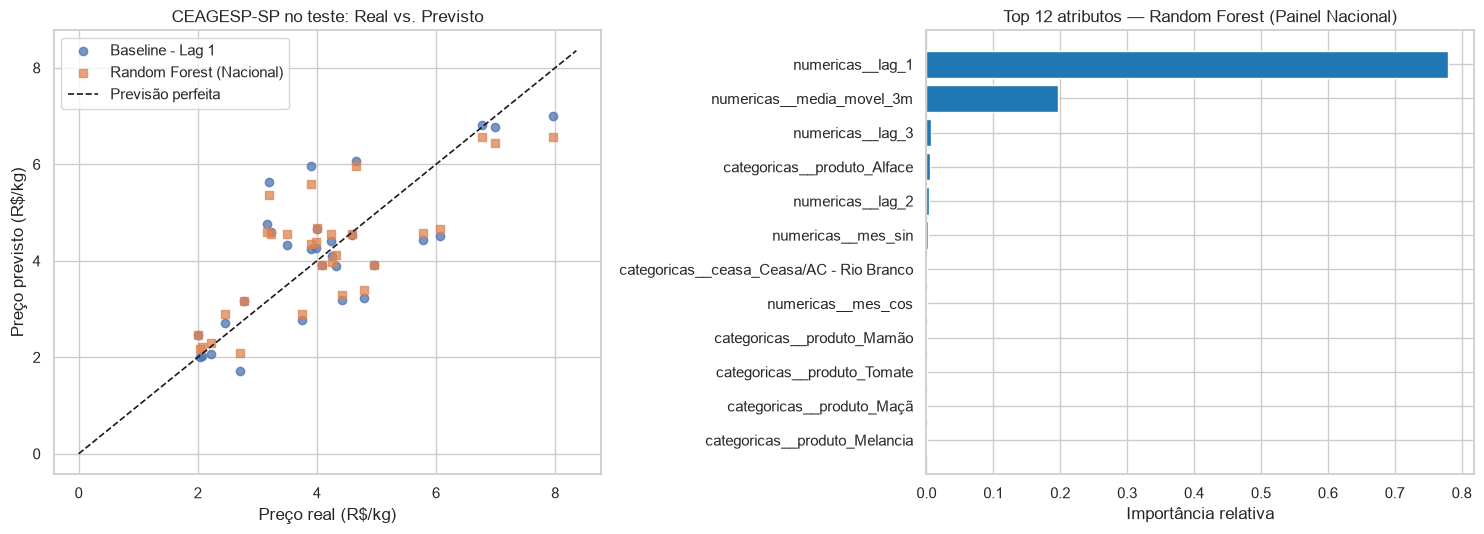

In [32]:
# 13.3. Gráficos diagnósticos no conjunto de teste

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Gráfico 1: Real vs Previsto na CEAGESP (painel nacional RF vs Baseline)
y_sp_real = y_teste_full_nacional[mascara_ceagesp].to_numpy()
y_sp_base = predicoes_teste_nacional["Baseline - Lag 1"][mascara_ceagesp]
y_sp_rf = predicoes_teste_nacional["Random Forest"][mascara_ceagesp]

limite_max = max(y_sp_real.max(), y_sp_base.max(), y_sp_rf.max()) * 1.05
axes[0].scatter(y_sp_real, y_sp_base, alpha=0.75, label="Baseline - Lag 1", marker="o")
axes[0].scatter(y_sp_real, y_sp_rf, alpha=0.75, label="Random Forest (Nacional)", marker="s")
axes[0].plot([0, limite_max], [0, limite_max], "k--", linewidth=1.2, label="Previsão perfeita")
axes[0].set_title("CEAGESP-SP no teste: Real vs. Previsto")
axes[0].set_xlabel("Preço real (R$/kg)")
axes[0].set_ylabel("Preço previsto (R$/kg)")
axes[0].legend()

# Gráfico 2: Top 12 importâncias de atributos do Random Forest (Painel Nacional)
rf_nacional_final = modelos_finais_nacional["Random Forest"]
nomes_features_nac = rf_nacional_final.named_steps["preprocessamento"].get_feature_names_out()
nomes_limpos = [
    n.replace("num__", "").replace("cat__", "")
    for n in nomes_features_nac
]
importancias = rf_nacional_final.named_steps["modelo"].feature_importances_

df_imp = (
    pd.DataFrame({"atributo": nomes_limpos, "importancia": importancias})
    .sort_values("importancia", ascending=False)
    .head(12)
    .sort_values("importancia", ascending=True)
)

axes[1].barh(df_imp["atributo"], df_imp["importancia"], color="tab:blue")
axes[1].set_title("Top 12 atributos — Random Forest (Painel Nacional)")
axes[1].set_xlabel("Importância relativa")

plt.tight_layout()
plt.show()

### 13.4. Interpretação dos resultados no conjunto de teste

No **painel nacional (julho a setembro de 2026, `n = 299`)**, os modelos supervisionados apresentaram desempenho superior ao `Baseline - Lag 1` no teste final, após o retreinamento com todos os dados disponíveis até junho de 2026.

- **Geral (`n = 299`):** `Ridge` apresentou o menor erro (`MAE = 0,7458`, `RMSE = 1,0600`, `MAPE = 17,65%`, `R² = 0,7406`), seguido por `Random Forest` (`MAE = 0,7841`, `R² = 0,7157`) e `Baseline - Lag 1` (`MAE = 0,7941`, `R² = 0,6805`).
- **9 CEASAs com cobertura integral (`n = 270`):** `Ridge` também apresentou o menor MAE (`0,7048`), com `RMSE = 0,9983` e `R² = 0,7252`.
- **CEAGESP — São Paulo (`n = 30`):** `Ridge` apresentou `MAE = 0,7193` e `R² = 0,6032`, enquanto o Baseline registrou `MAE = 0,7748` e `R² = 0,5228`. Na análise por entreposto, o `Ridge` obteve o menor MAE em 7 das 10 CEASAs com dados no teste.

**Comparação entre validação e teste:** a ordenação dos modelos não foi a mesma nas duas etapas. Na validação temporal do painel nacional (abril a junho de 2026), o `Baseline - Lag 1` apresentou o menor MAE (`0,7640`), seguido pelo `Random Forest` (`0,8284`) e pelo `Ridge` (`0,8730`). No teste final (julho a setembro de 2026), o `Ridge` apresentou o menor MAE (`0,7458`). Essa diferença indica que o desempenho relativo dos modelos variou entre os períodos avaliados. Após a validação, os modelos supervisionados foram retreinados com os dados disponíveis até junho de 2026 e avaliados no período de teste reservado. Portanto, os resultados do teste devem ser interpretados como uma avaliação posterior da capacidade de generalização, e não como critério para seleção retrospectiva do modelo.

No **experimento complementar CEAGESP-SP + INMET A701 (`n = 30`)**, os modelos supervisionados também apresentaram MAE inferior ao Baseline no teste final (`MAE = 0,7748`, `R² = 0,5228`):

- O menor erro foi registrado pelo `Random Forest - Com clima` (`MAE = 0,6412`, `RMSE = 0,8579`, `MAPE = 16,17%`, `R² = 0,6591`), seguido pelo `Random Forest - Sem clima` (`MAE = 0,6579`, `R² = 0,6557`).
- Na família `Ridge`, os resultados foram próximos: `MAE = 0,6986` com clima e `0,6953` sem clima. Os respectivos valores de `R²` foram `0,6188` e `0,6148`.
- Na análise por produto no teste (`n = 3` por item), algum modelo supervisionado apresentou resultado melhor que o Baseline nos dez produtos. O `Random Forest` teve destaque em Laranja, Banana, Cebola, Cenoura, Alface, Mamão e Tomate; o `Ridge`, em Batata, Maçã e Melancia. Como cada produto possui somente três observações no teste, esses resultados devem ser considerados diagnósticos e interpretados com cautela.

**Comparação entre validação e teste no experimento climático:** na validação temporal, o `Baseline - Lag 1` apresentou o menor MAE (`0,6199`). Já no teste final, o `Random Forest - Com clima` registrou o menor MAE (`0,6412`). Assim como no painel nacional, essa mudança evidencia que a comparação entre modelos depende do período avaliado. O resultado do teste não deve ser utilizado para justificar uma escolha retrospectiva do modelo. Além disso, o conjunto de teste climático contém apenas 30 observações, limitando a generalização dos resultados.

**Leitura diagnóstica:** o gráfico de importância de atributos do `Random Forest` nacional indica que `lag_1` e `media_movel_3m` concentram as maiores contribuições para as previsões do modelo. No experimento climático, a inclusão das variáveis meteorológicas da estação A701 esteve associada a uma redução discreta do MAE no `Random Forest` (de `0,6579` para `0,6412`), enquanto no `Ridge` o MAE foi ligeiramente maior com a inclusão do clima (de `0,6953` para `0,6986`). Portanto, não há evidência suficiente para afirmar que as variáveis climáticas melhoram o desempenho de todos os modelos. A estação A701 representa as condições meteorológicas da capital paulista, não necessariamente as condições das regiões produtoras que abastecem a CEAGESP.

## 14. Conexão com o NutriRota, limitações e próximos passos

### 14.1. Papel deste notebook na arquitetura do NutriRota
Os três notebooks do projeto cumprem papéis distintos e complementares:

1. **Notebook 1 (Brancoli et al.):** fornece a base empírica da composição e das taxas de desperdício evitável em feiras livres paulistanas, servindo como calibração científica para uma **estimativa experimental de desperdício**, sem simular uma série histórica inexistente.
2. **Notebook 2 (Prefeitura de São Paulo):** mapeia a distribuição territorial das feiras livres cadastradas no município, apoiando o recorte espacial e logístico para priorização de rotas de coleta e aproximação entre feirantes e organizações receptoras.
3. **Notebook 3 (CONAB + INMET A701 + CEAGESP):** modela **preços atacadistas mensais (R$/kg)** e analisa o contexto climático paulistano e a participação da CEAGESP no abastecimento nacional (entre ~25% e ~50% do volume em 9 dos 10 produtos no recorte trimestral observado, e ~11% a ~14% em banana).

Em conjunto, previsões de preço atacadista ajudam a sinalizar variações de mercado e oferta que afetam a dinâmica de comercialização de FLV, enquanto o histórico climático de calor e chuva (INMET A701) apoia a priorização operacional de alimentos mais sensíveis à conservação e de dias críticos nas feiras — **sem confundir previsão de preço (CONAB) com previsão direta de desperdício**.

### 14.2. Limitações metodológicas registradas
- **Ausência de série histórica aberta de desperdício real:** impediu treinar modelos supervisionados diretamente sobre toneladas desperdiçadas, justificando o uso de preços da CONAB na camada preditiva e de literatura científica (Brancoli et al.) para estimativa experimental de excedentes.
- **Extensão da série temporal (25 meses):** pouco mais de dois ciclos anuais limitam a captura de padrões sazonais mais longos e mantêm o recorte de teste da CEAGESP com 30 observações (`3` meses × `10` produtos).
- **Cobertura e qualidade dos dados:** exclusão de Brasília (`9,2%` de cobertura), ausência de dados válidos de Goiânia no período de teste (julho–setembro/2026) após tratamento de zeros suspeitos, e uma lacuna pontual de Melancia em Rio Branco no teste.
- **Escala espacial do clima:** a estação A701 (Mirante de Santana) reflete as condições ambientais da cidade de São Paulo, não capturando choques climáticos ocorridos diretamente nas regiões produtoras que abastecem a CEAGESP.

### 14.3. Próximos passos do projeto
- Integrar os indicadores territoriais (Notebook 2), as estimativas experimentais baseadas em literatura (Notebook 1) e os sinais de preço/clima (Notebook 3) no protótipo funcional da plataforma **NutriRota — Feira Inteligente**.
- Como evolução futura, incorporar séries mais longas da CONAB e registros operacionais reais de sobras/doações coletadas em feiras parceiras para calibrar modelos diretamente sobre excedentes evitáveis.

In [33]:
from pathlib import Path
import pandas as pd

# 1. Conferir se as avaliações finais foram executadas
if "df_teste_nacional" not in globals():
    raise NameError("Execute primeiro a célula 57: avaliação nacional.")

if "df_teste_ceagesp" not in globals():
    raise NameError("Execute primeiro a célula 58: avaliação CEAGESP + INMET.")

# 2. Preparar resultados do painel nacional
export_nacional = df_teste_nacional.rename(columns={
    "Recorte": "recorte",
    "Modelo": "modelo",
    "MAE": "mae",
    "RMSE": "rmse",
    "MAPE (%)": "mape_pct",
    "R²": "r2"
}).copy()

export_nacional["experimento"] = "CONAB - Painel Nacional"
export_nacional["periodo_teste"] = "Julho a setembro de 2026"
export_nacional["fonte"] = "CONAB"

# 3. Preparar resultados do experimento climático
export_ceagesp = df_teste_ceagesp.rename(columns={
    "Modelo": "modelo",
    "MAE": "mae",
    "RMSE": "rmse",
    "MAPE (%)": "mape_pct",
    "R²": "r2"
}).copy()

export_ceagesp["experimento"] = "CEAGESP + INMET"
export_ceagesp["recorte"] = "CEAGESP - São Paulo"
export_ceagesp["n"] = len(y_test)
export_ceagesp["periodo_teste"] = "Julho a setembro de 2026"
export_ceagesp["fonte"] = "CONAB + INMET A701"

# 4. Unificar os dois experimentos
colunas = [
    "experimento",
    "recorte",
    "n",
    "modelo",
    "mae",
    "rmse",
    "mape_pct",
    "r2",
    "periodo_teste",
    "fonte"
]

resultados_modelos = pd.concat(
    [
        export_nacional[colunas],
        export_ceagesp[colunas]
    ],
    ignore_index=True
)

# 5. Criar o diretório de destino, se necessário
if "PASTA_PROCESSED" in globals():
    pasta_destino = Path(PASTA_PROCESSED)
else:
    pasta_destino = Path.cwd().parent / "data" / "processed"

pasta_destino.mkdir(parents=True, exist_ok=True)

# 6. Exportar sem modificar nenhuma base original
arquivo_saida = pasta_destino / "resultados_modelos_conab.csv"

resultados_modelos.to_csv(
    arquivo_saida,
    index=False,
    encoding="utf-8-sig"
)

print("CSV exportado com sucesso!")
print(f"Arquivo: {arquivo_saida}")
print(f"Total de resultados: {len(resultados_modelos)}")

display(resultados_modelos.round(4))


CSV exportado com sucesso!
Arquivo: c:\Users\NovoAdmin\Desktop\FIAP\VSCode\global-solution-citizentech\data\processed\resultados_modelos_conab.csv
Total de resultados: 14


,experimento,recorte,n,modelo,mae,rmse,mape_pct,r2,periodo_teste,fonte
0,CONAB - Painel Nacional,Geral (todas com dados no teste),299,Baseline - Lag 1,0.7941,1.1764,18.9558,0.6805,Julho a setembro de 2026,CONAB
1,CONAB - Painel Nacional,Geral (todas com dados no teste),299,Ridge,0.7458,1.0600,17.6543,0.7406,Julho a setembro de 2026,CONAB
2,CONAB - Painel Nacional,Geral (todas com dados no teste),299,Random Forest,0.7841,1.1096,19.0158,0.7157,Julho a setembro de 2026,CONAB
3,CONAB - Painel Nacional,9 CEASAs com cobertura integral,270,Baseline - Lag 1,0.7622,1.1141,18.8436,0.6577,Julho a setembro de 2026,CONAB
4,CONAB - Painel Nacional,9 CEASAs com cobertura integral,270,Ridge,0.7048,0.9983,17.4170,0.7252,Julho a setembro de 2026,CONAB
5,CONAB - Painel Nacional,9 CEASAs com cobertura integral,270,Random Forest,0.7478,1.0461,18.8455,0.6982,Julho a setembro de 2026,CONAB
6,CONAB - Painel Nacional,CEAGESP — São Paulo,30,Baseline - Lag 1,0.7748,1.0151,19.9234,0.5228,Julho a setembro de 2026,CONAB
7,CONAB - Painel Nacional,CEAGESP — São Paulo,30,Ridge,0.7193,0.9256,18.3517,0.6032,Julho a setembro de 2026,CONAB
8,CONAB - Painel Nacional,CEAGESP — São Paulo,30,Random Forest,0.7650,0.9497,19.4556,0.5823,Julho a setembro de 2026,CONAB
9,CEAGESP + INMET,CEAGESP - São Paulo,30,Random Forest - Com clima,0.6412,0.8579,16.1689,0.6591,Julho a setembro de 2026,CONAB + INMET A701
